# Rush 4 — Segmentation des utilisateurs Instagram : usage et bien-être

**Epitech Paris · MSc MBA · Bootcamp Data · Octobre 2026**
Équipe : Mehdi · Bradley · Kiyani · Talel · Marco — commanditaire (fictif) : Direction Innovation d'Instagram

> **Question posée** : l'usage d'Instagram est-il lié au stress, au sommeil et au bonheur, et quels types d'utilisateurs les équipes produit doivent-elles distinguer pour concevoir pour chacun ?

**Comment lire ce notebook.** Il se lit de haut en bas et suit l'ordre des livrables du sujet :

| § | Section | Responsable (relecture) |
|---|---|---|
| 0 | Cadrage et critères de réussite | Marco (équipe) |
| 1 | Choix de données | Mehdi (Bradley, Marco) |
| 2 | Exploration de l'usage | Bradley (Mehdi) |
| 3 | Usage et bien-être | Bradley (Marco) |
| 4 | Feature engineering | Bradley (Mehdi) |
| 5 | Segmentation | Bradley (Mehdi) |
| 6 | Affectation d'un nouvel utilisateur | Mehdi (Bradley) |
| 7 | Évaluation selon nos critères | Bradley (Mehdi, Marco) |
| 8 | Au-delà du temps passé | Bradley (équipe) |
| 9 | Limites | Marco (Bradley, Kiyani) |
| 10 | Protection des données (RGPD UE / Royaume-Uni) | Kiyani · Marco |
| 11 | Recommandations produit | Talel (équipe) |
| 12 | Simulation économique (complément) | Talel (Marco) |
| 13 | Reproductibilité et exports | Mehdi (Bradley) |

**Exécution** : `Kernel → Restart & Run All`. Les deux extraits doivent être dans `data/` (ressources `rush-4/`). Toutes les graines aléatoires sont fixées (`SEED = 42`) : deux exécutions donnent les mêmes résultats (contrôlé au § 13).

**Confidentialité** : aucune ligne individuelle n'est affichée ; chaque agrégat affiché porte sur au moins `K_MIN = 100` utilisateurs (contrôle automatique, § 10.1).

In [1]:
# --- Imports et configuration ------------------------------------------------
import warnings, json, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.metrics import adjusted_rand_score, silhouette_score, mutual_info_score

warnings.filterwarnings("ignore")
SEED = 42
rng = np.random.default_rng(SEED)
K_MIN = 100                      # taille minimale de tout groupe affiché

ROOT = Path("..") if (Path("..") / "data").exists() else Path(".")
DATA_DIR, FIG_DIR, OUT_DIR = ROOT / "data", ROOT / "figures", ROOT / "outputs"
FIG_DIR.mkdir(exist_ok=True); OUT_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Charte graphique : 2 couleurs catégorielles (style d'usage), une rampe bleue pour l'intensité
C_SPEC, C_CREA = "#2a78d6", "#eb6834"      # Spectateurs / Créateurs-Reels
C_INK, C_MUTED, C_GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUES = ["#b7d3f2", "#6fa6e6", "#2a78d6", "#1b4f8f"]
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "axes.edgecolor": C_MUTED,
                     "axes.labelcolor": C_INK, "xtick.color": C_MUTED, "ytick.color": C_MUTED,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "axes.grid": True,
                     "grid.color": C_GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=160, bbox_inches="tight", facecolor="white")

def check_k(counts, what=""):
    # Garde-fou confidentialité : refuse d'afficher un agrégat portant sur moins de K_MIN utilisateurs
    counts = pd.Series(counts)
    assert (counts >= K_MIN).all(), f"{what} : groupe(s) < {K_MIN} utilisateurs — affichage refusé"
    return True

print("Données :", DATA_DIR.resolve())

Données : data


## 0. Cadrage et critères de réussite

**Ce qu'on nous demande** (kick-off) : une segmentation *fondée sur l'usage*, qui *explique* le lien usage ↔ bien-être, *utilisable* par les équipes produit, *assignable à tout utilisateur* avec les seules données détenues sur tous, et défendable devant une direction qui contestera tout.

**Deux routes possibles** : (A) regrouper les utilisateurs en profils d'usage (clustering) ; (B) prédire un indicateur de bien-être à partir de l'usage et découper la prédiction. Nous testons les deux, plus la référence imposée (classement par temps passé), puis retenons une segmentation **hybride** (§ 5.4) et justifions pourquoi elle répond mieux.

**Personne ne nous a dit ce qu'est une bonne segmentation** : nous fixons donc nos critères *avant* de regarder les résultats, avec un seuil vérifiable sur les données pour chacun.

| # | Critère | Mesure vérifiable | Seuil |
|---|---|---|---|
| C1 | **Assignable à tous** | les segments n'utilisent que des variables d'activité détenues pour tous ; fonction d'affectation testée sur des utilisateurs jamais vus | 0 variable bien-être/santé/profil en entrée ; accord ≥ 95 % sur échantillon test |
| C2 | **Taille actionnable et non isolante** | part du plus petit segment | ≥ 5 % des utilisateurs |
| C3 | **Stabilité** | ARI moyen entre la segmentation de référence et 10 ré-estimations sur des sous-échantillons de 50 % | ≥ 0,90 |
| C4 | **Lien avec le bien-être** | η² du stress expliqué par les segments, rapporté à celui du classement par temps passé à nombre de groupes égal | ≥ 90 % de la référence |
| C5 | **Valeur au-delà du temps passé** | écart de stress entre styles *à temps passé égal* (IC 95 %), puis *à temps passé et âge égaux* | IC excluant 0 et écart ≥ 2 points (échelle 0-40) dans les deux cas |
| C6 | **Différenciation comportementale** | d de Cohen entre styles sur les variables de style | ≥ 0,8 (« grand effet ») |
| C7 | **Reproductibilité** | empreinte (hash) des étiquettes identique à chaque exécution | identique |
| C8 | **Protection des données** | aucun agrégat < 100 utilisateurs ; segments sans variable de santé ni de profil sensible en entrée ; risque d'inférence santé mesuré et documenté | tous respectés |

## 1. Choix de données

L'équipe privacy fournit **deux répliques synthétiques** du même panel (200 000 utilisateurs chacune). L'une a subi un nettoyage *non documenté* ; elles ne concordent pas entièrement. Nous devons décider **laquelle croire, sur quels champs**, et le documenter.

### 1.1 Inventaire des deux extraits

In [2]:
FILE_A = DATA_DIR / "instagram_users_lifestyleSafe.csv"   # extrait A
FILE_B = DATA_DIR / "instagram_usage_lifestyleSafe.csv"   # extrait B
A = pd.read_csv(FILE_A)
B = pd.read_csv(FILE_B)

inventaire = pd.DataFrame({
    "lignes": [len(A), len(B)],
    "colonnes": [A.shape[1], B.shape[1]],
    "user_id uniques": [A.user_id.nunique(), B.user_id.nunique()],
    "valeurs manquantes": [int(A.isna().sum().sum()), int(B.isna().sum().sum())],
    "doublons (hors user_id)": [int(A.drop(columns="user_id").duplicated().sum()),
                                int(B.drop(columns="user_id").duplicated().sum())],
}, index=["A · users", "B · usage"])
print("Mêmes colonnes, même ordre :", list(A.columns) == list(B.columns))
print("Mêmes types :", (A.dtypes == B.dtypes).all())
print("Mêmes identifiants :", set(A.user_id) == set(B.user_id))
inventaire

Mêmes colonnes, même ordre : True
Mêmes types : True
Mêmes identifiants : True


,lignes,colonnes,user_id uniques,valeurs manquantes,doublons (hors user_id)
A · users,200000,58,200000,0,0
B · usage,200000,58,200000,0,0


In [3]:
# Familles de variables : qui est détenu pour tous, qui vient du panel volontaire
USAGE = ["daily_active_minutes_instagram", "sessions_per_day", "average_session_length_minutes",
         "posts_created_per_week", "reels_watched_per_day", "stories_viewed_per_day",
         "likes_given_per_day", "comments_written_per_day", "dms_sent_per_week", "dms_received_per_week",
         "ads_viewed_per_day", "ads_clicked_per_day", "time_on_feed_per_day", "time_on_explore_per_day",
         "time_on_messages_per_day", "time_on_reels_per_day", "notification_response_rate"]
ACCOUNT = ["followers_count", "following_count", "uses_premium_features", "account_creation_year",
           "last_login_date", "content_type_preference", "preferred_content_theme", "privacy_setting_level",
           "two_factor_auth_enabled", "biometric_login_used", "linked_accounts_count",
           "subscription_status", "user_engagement_score"]
PROFILE = ["age", "gender", "country", "urban_rural", "income_level", "employment_status",
           "education_level", "relationship_status", "has_children"]
WELLBEING = ["perceived_stress_score", "self_reported_happiness", "sleep_hours_per_night"]
HEALTH_LIFESTYLE = ["exercise_hours_per_week", "diet_quality", "smoking", "alcohol_frequency",
                    "body_mass_index", "blood_pressure_systolic", "blood_pressure_diastolic",
                    "daily_steps_count", "weekly_work_hours", "hobbies_count", "social_events_per_month",
                    "books_read_per_year", "volunteer_hours_per_month", "travel_frequency_per_year"]
OTHER = ["user_id", "app_name"]
assert sorted(USAGE + ACCOUNT + PROFILE + WELLBEING + HEALTH_LIFESTYLE + OTHER) == sorted(A.columns)

familles = pd.DataFrame([
    ("Activité in-app", len(USAGE), "tous les utilisateurs", "oui"),
    ("Compte / paramètres", len(ACCOUNT), "tous les utilisateurs", "oui"),
    ("Profil déclaratif", len(PROFILE), "tous (déclaratif)", "non — description seulement"),
    ("Bien-être (stress, bonheur, sommeil)", len(WELLBEING), "panel volontaire", "non — évaluation seulement"),
    ("Santé et mode de vie", len(HEALTH_LIFESTYLE), "panel volontaire", "non"),
], columns=["famille", "nb variables", "détenu pour", "utilisable pour construire les segments"])
familles

,famille,nb variables,détenu pour,utilisable pour construire les segments
0,Activité in-app,17,tous les utilisateurs,oui
1,Compte / paramètres,13,tous les utilisateurs,oui
2,Profil déclaratif,9,tous (déclaratif),non — description seulement
3,"Bien-être (stress, bonheur, sommeil)",3,panel volontaire,non — évaluation seulement
4,Santé et mode de vie,14,panel volontaire,non


### 1.2 Comparaison des deux versions, champ par champ

In [4]:
a = A.set_index("user_id").sort_index()
b = B.set_index("user_id").sort_index()
diff = pd.Series({c: (a[c] != b[c]).mean() * 100 for c in a.columns})
fam = {**{c: "activité" for c in USAGE}, **{c: "compte" for c in ACCOUNT}, **{c: "profil" for c in PROFILE},
       **{c: "bien-être" for c in WELLBEING}, **{c: "santé / mode de vie" for c in HEALTH_LIFESTYLE},
       "app_name": "autre"}
ecarts = (pd.DataFrame({"famille": pd.Series(fam), "% de lignes différentes": diff})
          .query("`% de lignes différentes` > 0").sort_values("% de lignes différentes", ascending=False))
print(f"{(diff == 0).sum()} champs sur {len(diff)} sont strictement identiques dans A et B.")
print("Activité + bien-être identiques :", bool((a[USAGE + WELLBEING] == b[USAGE + WELLBEING]).all().all()))
ecarts

51 champs sur 57 sont strictement identiques dans A et B.
Activité + bien-être identiques : True


,famille,% de lignes différentes
account_creation_year,compte,15.886
employment_status,profil,9.457
weekly_work_hours,santé / mode de vie,9.456
relationship_status,profil,3.311
has_children,profil,2.664
education_level,profil,0.602


In [5]:
# Où se concentrent les écarts ? (part de lignes modifiées par tranche d'âge, en %)
AGE_BANDS = pd.cut(a.age, [12, 17, 22, 30, 65], labels=["13-17", "18-22", "23-30", "31-65"])
check_k(AGE_BANDS.value_counts(), "tranches d'âge")
loc = pd.DataFrame({c: (a[c] != b[c]).groupby(AGE_BANDS, observed=True).mean() * 100 for c in ecarts.index}).T.round(1)
loc.columns = [f"{c} ans (%)" for c in loc.columns]
loc

,13-17 ans (%),18-22 ans (%),23-30 ans (%),31-65 ans (%)
account_creation_year,87.200,55.500,16.200,0.000
employment_status,100.000,0.000,0.000,0.000
weekly_work_hours,100.000,0.000,0.000,0.000
relationship_status,35.000,0.000,0.000,0.000
has_children,28.200,0.000,0.000,0.000
education_level,3.000,2.900,0.300,0.000


In [6]:
# Ce que dit chaque version des 13-17 ans (taux agrégés sur 18 913 mineurs)
mineurs = a.age < 18
def taux_mineurs(df):
    d = df[mineurs]
    return pd.Series({
        "en emploi temps plein (%)": (d.employment_status == "Full-time employed").mean() * 100,
        "heures travaillées / sem. (moyenne)": d.weekly_work_hours.mean(),
        "mariés, divorcés ou veufs (%)": d.relationship_status.isin(["Married", "Divorced", "Widowed"]).mean() * 100,
        "avec enfants (%)": (d.has_children == "Yes").mean() * 100,
        "titulaires d'un doctorat (%)": (d.education_level == "PhD").mean() * 100,
        "titulaires d'un Master (%)": (d.education_level == "Master’s").mean() * 100,
    })
check_k([mineurs.sum()], "mineurs")
pd.DataFrame({"A (users)": taux_mineurs(a), "B (usage)": taux_mineurs(b)}).round(1)

,A (users),B (usage)
en emploi temps plein (%),0.000,45.400
heures travaillées / sem. (moyenne),0.000,40.000
"mariés, divorcés ou veufs (%)",0.000,35.000
avec enfants (%),0.000,28.200
titulaires d'un doctorat (%),0.000,3.000
titulaires d'un Master (%),11.800,11.800


In [7]:
# Libellés d'éducation : A introduit de nouvelles modalités, uniquement là où B avait « PhD » avant 23 ans
edu = pd.crosstab(a.education_level, b.education_level)
print("Modalités présentes dans A mais pas dans B :", sorted(set(a.education_level) - set(b.education_level)))
edu.loc[["Bachelor", "High School", "Secondary"], ["PhD"]]

Modalités présentes dans A mais pas dans B : ['Bachelor', 'High School', 'Secondary']


education_level,PhD
education_level,
Bachelor,299
High School,329
Secondary,575


In [8]:
# Année de création du compte : âge implicite à la création
last_login = pd.to_datetime(a.last_login_date)
annee_naissance = last_login.dt.year - a.age
chg = a.account_creation_year != b.account_creation_year
acy = pd.DataFrame({
    "comptes créés avant 13 ans": [((b.account_creation_year - annee_naissance) < 13).sum(),
                                   ((a.account_creation_year - annee_naissance) < 13).sum()],
    "comptes créés après la dernière connexion": [(b.account_creation_year > last_login.dt.year).sum(),
                                                  (a.account_creation_year > last_login.dt.year).sum()],
    "max année de création": [b.account_creation_year.max(), a.account_creation_year.max()],
}, index=["B (usage)", "A (users)"])
age_creation_A = (a.account_creation_year - annee_naissance)[chg]
print(f"Lignes modifiées : {chg.sum():,} ; dans A, l'âge implicite à la création y vaut "
      f"{age_creation_A.min():.0f} à {age_creation_A.max():.0f} ans → valeur recalculée, pas observée.")
acy

Lignes modifiées : 31,772 ; dans A, l'âge implicite à la création y vaut 13 à 14 ans → valeur recalculée, pas observée.


,comptes créés avant 13 ans,comptes créés après la dernière connexion,max année de création
B (usage),27989,0,2025
A (users),0,3724,2026


**Lecture.** Les 52 champs d'activité, de compte, de bien-être et de santé sont **strictement identiques** dans les deux extraits : le nettoyage non documenté n'a touché que **6 champs de profil**, et quasi exclusivement les 13-30 ans. L'extrait **A (`users`) est la version nettoyée** :

* il a recodé les **13-17 ans** en « Not employed », 0 h de travail, célibataires, sans enfants — B leur attribuait un emploi à temps plein (45 %), 40 h/semaine, des mariages et des enfants (implausible) ;
* il a remplacé les **doctorats avant 23 ans** par trois *nouveaux* libellés hétérogènes (`Bachelor`, `High School`, `Secondary`) — doublons de modalités existantes, nettoyage incomplet (il reste 12 % de « Master » chez les 13-17 ans) ;
* il a **décalé l'année de création** des comptes ouverts avant 13 ans pour la ramener à 13-14 ans. Cette correction est mécanique : elle crée **3 724 comptes « créés » après leur dernière connexion** (impossible) et efface une information réelle (des moins de 13 ans contournent les CGU).

**Décision (champ par champ)**

| Champ | Version retenue | Raison |
|---|---|---|
| Activité, compte (hors année de création), bien-être, santé | A = B | identiques : aucun arbitrage, **nos résultats de segmentation ne dépendent pas du choix** |
| `employment_status`, `weekly_work_hours`, `relationship_status`, `has_children` | **A** | B est incohérent pour les 13-17 ans ; la valeur A est une *imputation* (signalée), pas une observation |
| `education_level` | **A, libellés harmonisés** (`Bachelor`→`Bachelor’s`, `High School`/`Secondary`→`High school`) | B affiche des doctorats à 13 ans ; A reste partiel → champ jugé **peu fiable**, utilisé nulle part |
| `account_creation_year` | **B** | la correction A crée des dates impossibles ; B est plausible (comptes ouverts avant 13 ans) — signal utile pour la protection des mineurs |

Aucun des champs arbitrés n'entre dans la segmentation (§ 4) : ils ne servent qu'à décrire les segments et à l'analyse RGPD.

In [9]:
D = a.copy()
D["account_creation_year"] = b["account_creation_year"]
D["education_level"] = D["education_level"].replace({"Bachelor": "Bachelor’s", "High School": "High school",
                                                     "Secondary": "High school"})
D["mineur"] = D.age < 18
D["age_band"] = AGE_BANDS
print("Jeu de travail :", D.shape, "| mineurs (13-17) :", f"{D.mineur.mean():.1%}")
del A, B

Jeu de travail : (200000, 59) | mineurs (13-17) : 9.5%


### 1.3 Contrôle qualité : manquants, doublons, distributions, incohérences

In [10]:
m = D.daily_active_minutes_instagram
sections = D[["time_on_feed_per_day", "time_on_explore_per_day", "time_on_messages_per_day", "time_on_reels_per_day"]]
eng_proxy = (D.likes_given_per_day + D.comments_written_per_day + D.posts_created_per_week) / m
qc = pd.DataFrame([
    ("Valeurs manquantes", "0 sur tout le fichier", "aucun traitement"),
    ("Doublons", "0 identifiant dupliqué", "aucun traitement"),
    ("sessions × durée moyenne / minutes",
     f"médiane {(D.sessions_per_day * D.average_session_length_minutes / m).median():.3f} (p1-p99 : "
     f"{(D.sessions_per_day * D.average_session_length_minutes / m).quantile(.01):.3f}-"
     f"{(D.sessions_per_day * D.average_session_length_minutes / m).quantile(.99):.3f})",
     "durée de session = minutes / sessions → variable dérivée"),
    ("Somme des 4 temps par section / minutes",
     f"médiane {(sections.sum(axis=1) / m).median():.2f} (min {(sections.sum(axis=1) / m).min():.2f}, max {(sections.sum(axis=1) / m).max():.2f})",
     "les sections ne s'additionnent pas au total → seules les parts relatives sont exploitables"),
    ("user_engagement_score vs (likes+commentaires+posts)/minutes",
     f"corrélation {np.corrcoef(eng_proxy, D.user_engagement_score)[0, 1]:.3f}",
     "score dérivé de l'activité par minute → redondant, écarté"),
    ("daily_steps_count", f"écart-type {D.daily_steps_count.std():.0f} pas autour de {D.daily_steps_count.mean():.0f}",
     "quasi constant → non informatif"),
    ("Stress (0-40) et bonheur (1-10)",
     f"bonheur : chaque note = {D.self_reported_happiness.value_counts(normalize=True).min():.1%} à "
     f"{D.self_reported_happiness.value_counts(normalize=True).max():.1%}",
     "marges uniformes : signature du générateur synthétique"),
    ("ads_viewed_per_day = 0", f"{(D.ads_viewed_per_day == 0).sum():,} utilisateurs", "taux de clic mis à 0 (pas de division par 0)"),
    ("Âge", f"{D.age.min()} à {D.age.max()} ans", "pas de moins de 13 ans dans le panel"),
    ("Minutes actives au plancher (5 min)", f"{(m == m.min()).mean():.1%} des utilisateurs", "valeur tronquée par le générateur → quantiles calculés sur les rangs"),
], columns=["contrôle", "constat", "traitement"])
qc

,contrôle,constat,traitement
0,Valeurs manquantes,0 sur tout le fichier,aucun traitement
1,Doublons,0 identifiant dupliqué,aucun traitement
2,sessions × durée moyenne / minutes,médiane 1.000 (p1-p99 : 0.996-1.004),durée de session = minutes / sessions → variab...
3,Somme des 4 temps par section / minutes,"médiane 1.18 (min 0.82, max 1.57)",les sections ne s'additionnent pas au total → ...
4,user_engagement_score vs (likes+commentaires+p...,corrélation 0.994,score dérivé de l'activité par minute → redond...
5,daily_steps_count,écart-type 89 pas autour de 8000,quasi constant → non informatif
6,Stress (0-40) et bonheur (1-10),bonheur : chaque note = 9.9% à 10.1%,marges uniformes : signature du générateur syn...
7,ads_viewed_per_day = 0,68 utilisateurs,taux de clic mis à 0 (pas de division par 0)
8,Âge,13 à 65 ans,pas de moins de 13 ans dans le panel
9,Minutes actives au plancher (5 min),5.4% des utilisateurs,valeur tronquée par le générateur → quantiles ...


## 2. Exploration de l'usage

Les distributions sont décrites de façon agrégée. Question préalable à toute segmentation : **combien de dimensions d'usage indépendantes existe-t-il vraiment ?**

1re composante principale : 69% de la variance des 18 variables d'usage
Corrélation (Spearman) médiane entre les 15 variables de volume : 0.84


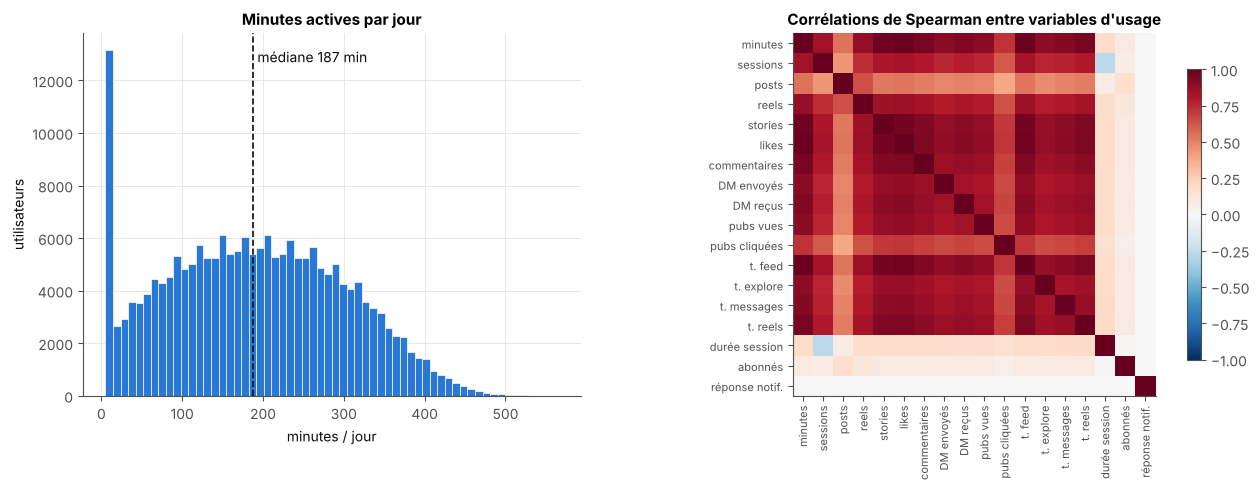

In [11]:
CORE_USAGE = ["daily_active_minutes_instagram", "sessions_per_day", "posts_created_per_week",
              "reels_watched_per_day", "stories_viewed_per_day", "likes_given_per_day",
              "comments_written_per_day", "dms_sent_per_week", "dms_received_per_week", "ads_viewed_per_day",
              "ads_clicked_per_day", "time_on_feed_per_day", "time_on_explore_per_day",
              "time_on_messages_per_day", "time_on_reels_per_day", "average_session_length_minutes",
              "followers_count", "notification_response_rate"]
corr = D[CORE_USAGE].corr(method="spearman")
pca = PCA(random_state=SEED).fit(StandardScaler().fit_transform(np.log1p(D[CORE_USAGE])))
print(f"1re composante principale : {pca.explained_variance_ratio_[0]:.0%} de la variance des 18 variables d'usage")
print(f"Corrélation (Spearman) médiane entre les 15 variables de volume : "
      f"{corr.iloc[:15, :15].where(~np.eye(15, dtype=bool)).stack().median():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
ax.hist(m, bins=60, color=C_SPEC, edgecolor="white", linewidth=0.5)
ax.axvline(m.median(), color=C_INK, lw=1.2, ls="--")
ax.text(m.median() + 6, ax.get_ylim()[1] * 0.92, f"médiane {m.median():.0f} min", color=C_INK)
ax.set(title="Minutes actives par jour", xlabel="minutes / jour", ylabel="utilisateurs")
ax = axes[1]
labels = ["minutes", "sessions", "posts", "reels", "stories", "likes", "commentaires", "DM envoyés",
          "DM reçus", "pubs vues", "pubs cliquées", "t. feed", "t. explore", "t. messages", "t. reels",
          "durée session", "abonnés", "réponse notif."]
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=90, fontsize=8); ax.set_yticks(range(len(labels)), labels, fontsize=8)
ax.grid(False); ax.set_title("Corrélations de Spearman entre variables d'usage")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout(); savefig(fig, "fig01_usage_distribution_correlations"); plt.show()

In [12]:
# Usage par tranche d'âge (médianes agrégées)
check_k(D.age_band.value_counts(), "tranches d'âge")
usage_age = D.groupby("age_band", observed=True).agg(
    effectif=("age", "size"), minutes=("daily_active_minutes_instagram", "median"),
    posts_semaine=("posts_created_per_week", "median"), reels_jour=("reels_watched_per_day", "median"),
    sessions_jour=("sessions_per_day", "median"))
usage_age

,effectif,minutes,posts_semaine,reels_jour,sessions_jour
age_band,,,,,
13-17,18913,223.000,10.000,253.000,10.000
18-22,18630,216.000,10.000,249.000,10.000
23-30,30485,206.000,6.000,235.000,10.000
31-65,131972,173.000,4.000,143.000,8.000


**Lecture.** Une seule dimension domine : **l'intensité d'usage**. Minutes, likes, stories, commentaires, DM, publicités et temps par section évoluent ensemble (ρ médian ≈ 0,84 ; la 1re composante résume 69 % de la variance). Les comportements qui s'en écartent sont rares : **création de posts** (ρ ≈ 0,54 avec le temps) et **volume de Reels** (qui suit le temps mais dépend aussi fortement de l'âge : 250 Reels/jour chez les 13-22 ans contre 143 après 30 ans), **audience** (abonnés, quasi indépendante) et **réactivité aux notifications** (indépendante de tout). Conséquence pour la segmentation : un clustering naïf sur les volumes redécouvrira surtout le temps passé (vérifié au § 5.2).

## 3. Usage et bien-être

Les trois indicateurs du sujet : **stress perçu** (0-40), **bonheur déclaré** (1-10), **sommeil** (heures/nuit). Ils viennent du panel volontaire et ne servent qu'à *évaluer* la segmentation, jamais à la construire.

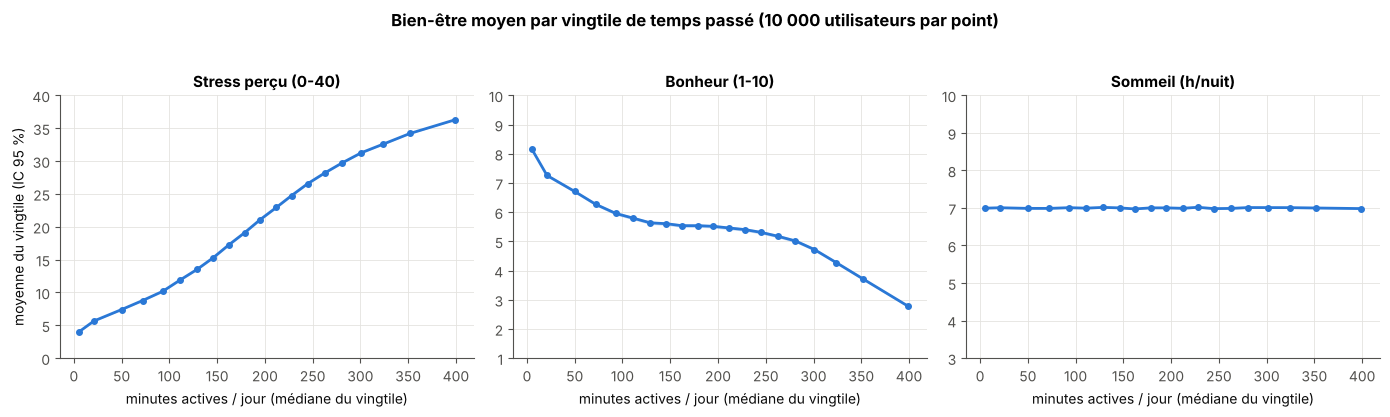

In [13]:
WB_LABELS = {"perceived_stress_score": "Stress perçu (0-40)", "self_reported_happiness": "Bonheur (1-10)",
             "sleep_hours_per_night": "Sommeil (h/nuit)"}
vingtiles = pd.qcut(m.rank(method="first"), 20, labels=False)  # rangs : 5 % des utilisateurs ont la valeur plancher (5 min)
check_k(vingtiles.value_counts(), "vingtiles de temps")
g = D.groupby(vingtiles)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, y in zip(axes, WB_LABELS):
    mu, se, x = g[y].mean(), g[y].sem(), g["daily_active_minutes_instagram"].median()
    ax.fill_between(x, mu - 1.96 * se, mu + 1.96 * se, color=C_SPEC, alpha=0.25, lw=0)
    ax.plot(x, mu, color=C_SPEC, lw=2, marker="o", ms=4)
    ax.set(title=WB_LABELS[y], xlabel="minutes actives / jour (médiane du vingtile)")
    lo, hi = D[y].min(), D[y].max(); ax.set_ylim(lo, hi)
axes[0].set_ylabel("moyenne du vingtile (IC 95 %)")
fig.suptitle("Bien-être moyen par vingtile de temps passé (10 000 utilisateurs par point)", y=1.03, fontweight="bold")
fig.tight_layout(); savefig(fig, "fig02_bienetre_vs_temps"); plt.show()

In [14]:
# Associations (Spearman) avec IC 95 % (transformation de Fisher)
def spearman_ci(x, y):
    r = pd.Series(x).corr(pd.Series(y), method="spearman"); n = len(x); z = np.arctanh(r); s = 1 / np.sqrt(n - 3)
    return r, np.tanh(z - 1.96 * s), np.tanh(z + 1.96 * s)
rows = []
for v in ["daily_active_minutes_instagram", "sessions_per_day", "likes_given_per_day", "time_on_reels_per_day",
          "posts_created_per_week", "reels_watched_per_day", "average_session_length_minutes",
          "followers_count", "notification_response_rate", "age"]:
    for y in WB_LABELS:
        r, lo, hi = spearman_ci(D[v].values, D[y].values)
        rows.append((v, WB_LABELS[y], r, lo, hi))
assoc = (pd.DataFrame(rows, columns=["variable", "indicateur", "rho", "IC bas", "IC haut"])
         .pivot(index="variable", columns="indicateur", values="rho").round(3))
assoc.sort_values("Stress perçu (0-40)", ascending=False)

indicateur,Bonheur (1-10),Sommeil (h/nuit),Stress perçu (0-40)
variable,,,
daily_active_minutes_instagram,-0.361,-0.001,0.841
likes_given_per_day,-0.355,-0.001,0.826
time_on_reels_per_day,-0.342,-0.002,0.797
sessions_per_day,-0.310,-0.002,0.704
reels_watched_per_day,-0.291,-0.002,0.673
posts_created_per_week,-0.144,0.000,0.404
average_session_length_minutes,-0.097,0.002,0.157
followers_count,-0.028,0.002,0.068
age,-0.001,0.005,-0.002


**Actif ou passif ?** Une hypothèse fréquente : la consommation passive (scroll, Stories, Reels) serait liée au stress, l'engagement actif (messages, commentaires) non. Nous la testons, et nous vérifions au passage ce que mesure vraiment `user_engagement_score`.

In [15]:
actif_passif = pd.DataFrame([
    ("passif", "Temps sur le fil", "time_on_feed_per_day"), ("passif", "Stories vues", "stories_viewed_per_day"),
    ("passif", "Temps sur les Reels", "time_on_reels_per_day"), ("actif", "Likes donnés", "likes_given_per_day"),
    ("actif", "Commentaires écrits", "comments_written_per_day"), ("actif", "Messages envoyés", "dms_sent_per_week"),
    ("actif", "Posts publiés", "posts_created_per_week"), ("ratio", "Score d'engagement (par minute)", "user_engagement_score"),
], columns=["type", "comportement", "variable"])
actif_passif["rho avec le stress"] = [D[v].corr(D.perceived_stress_score, method="spearman") for v in actif_passif.variable]
actif_passif["rho avec le temps passé"] = [D[v].corr(m, method="spearman") for v in actif_passif.variable]
print("Le score d'engagement est un ratio par minute : corrélation avec (likes + commentaires + posts) / minutes =",
      round(np.corrcoef(eng_proxy, D.user_engagement_score)[0, 1], 3))
actif_passif.drop(columns="variable").round(2)

Le score d'engagement est un ratio par minute : corrélation avec (likes + commentaires + posts) / minutes = 0.994


,type,comportement,rho avec le stress,rho avec le temps passé
0,passif,Temps sur le fil,0.820,0.980
1,passif,Stories vues,0.820,0.970
2,passif,Temps sur les Reels,0.800,0.950
3,actif,Likes donnés,0.830,0.980
4,actif,Commentaires écrits,0.800,0.950
5,actif,Messages envoyés,0.760,0.910
6,actif,Posts publiés,0.400,0.540
7,ratio,Score d'engagement (par minute),-0.690,-0.800


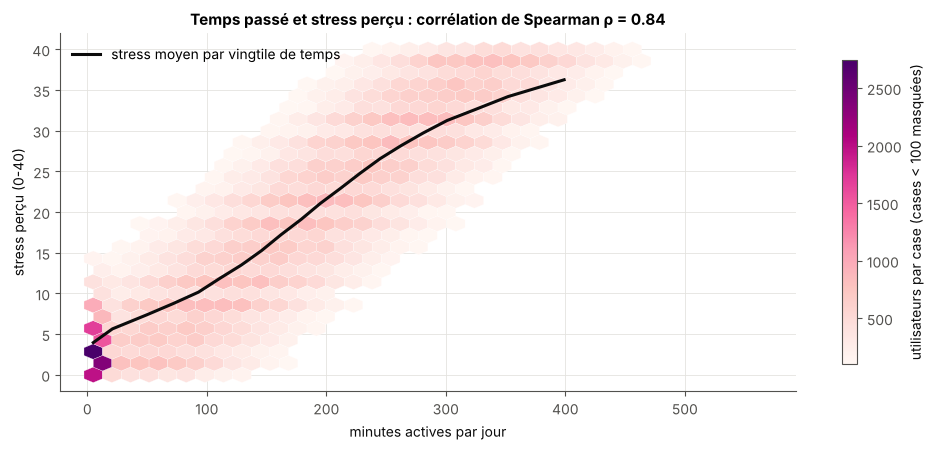

In [16]:
# Densité temps passé × stress : cases agrégées, aucune case affichée sous K_MIN utilisateurs
fig, ax = plt.subplots(figsize=(10, 4.6))
hb = ax.hexbin(m, D.perceived_stress_score, gridsize=(36, 14), mincnt=K_MIN, cmap="RdPu", linewidths=0.2, edgecolors="white")
g20 = D.groupby(vingtiles).agg(x=("daily_active_minutes_instagram", "median"), y=("perceived_stress_score", "mean"))
ax.plot(g20.x, g20.y, color=C_INK, lw=2.2, label="stress moyen par vingtile de temps")
rho_ts = m.corr(D.perceived_stress_score, method="spearman")
ax.set(title=f"Temps passé et stress perçu : corrélation de Spearman ρ = {rho_ts:.2f}",
       xlabel="minutes actives par jour", ylabel="stress perçu (0-40)")
cb = fig.colorbar(hb, ax=ax, shrink=0.85); cb.set_label(f"utilisateurs par case (cases < {K_MIN} masquées)")
ax.legend(loc="upper left"); fig.tight_layout(); savefig(fig, "fig07_densite_temps_stress"); plt.show()

In [17]:
# Pouvoir prédictif : temps seul vs toute l'activité (validation croisée 5 plis, échantillon de 60 000)
S = D.sample(60_000, random_state=SEED)
kf = KFold(5, shuffle=True, random_state=SEED)
ALL_ACTIVITY = USAGE + ["followers_count", "following_count", "linked_accounts_count"]
def cv_r2(X, y):
    return cross_val_score(HistGradientBoostingRegressor(random_state=SEED), X, y, cv=kf, scoring="r2").mean()
pred = pd.DataFrame({WB_LABELS[y]: {"temps passé seul": cv_r2(S[["daily_active_minutes_instagram"]], S[y]),
                                    "toute l'activité (20 variables)": cv_r2(S[ALL_ACTIVITY], S[y]),
                                    "âge seul": cv_r2(S[["age"]], S[y])} for y in WB_LABELS}).T
pred["gain de l'activité au-delà du temps"] = pred["toute l'activité (20 variables)"] - pred["temps passé seul"]
pred.round(3)

,temps passé seul,toute l'activité (20 variables),âge seul,gain de l'activité au-delà du temps
Stress perçu (0-40),0.706,0.725,-0.001,0.019
Bonheur (1-10),0.157,0.164,-0.001,0.006
Sommeil (h/nuit),-0.001,-0.001,-0.001,0.000


In [18]:
# Robustesse : la relation temps → stress tient-elle dans chaque sous-population ?
rob = []
for col in ["age_band", "gender", "country"]:
    for k, d in D.groupby(col, observed=True):
        if len(d) >= K_MIN:
            rob.append((col, k, len(d), d.daily_active_minutes_instagram.corr(d.perceived_stress_score, method="spearman"),
                        d.daily_active_minutes_instagram.corr(d.self_reported_happiness, method="spearman")))
rob = pd.DataFrame(rob, columns=["dimension", "modalité", "effectif", "rho temps-stress", "rho temps-bonheur"])
print(f"rho temps-stress : de {rob['rho temps-stress'].min():.3f} à {rob['rho temps-stress'].max():.3f} sur {len(rob)} sous-groupes")
print(f"rho temps-bonheur : de {rob['rho temps-bonheur'].min():.3f} à {rob['rho temps-bonheur'].max():.3f}")
rob.groupby("dimension")[["rho temps-stress", "rho temps-bonheur"]].agg(["min", "max"]).round(3)

rho temps-stress : de 0.836 à 0.861 sur 18 sous-groupes
rho temps-bonheur : de -0.377 à -0.348


rho temps-stress       rho temps-bonheur       
                       min   max               min    max
dimension                                                
age_band             0.850 0.861            -0.377 -0.364
country              0.836 0.843            -0.377 -0.348
gender               0.837 0.841            -0.366 -0.360

In [19]:
# Un artefact du générateur synthétique : la structure n'est préservée que deux à deux
def partial_corr(x, y, z):
    Z = np.c_[np.ones(len(z)), z]
    rx = x - Z @ np.linalg.lstsq(Z, x, rcond=None)[0]; ry = y - Z @ np.linalg.lstsq(Z, y, rcond=None)[0]
    return np.corrcoef(rx, ry)[0, 1]
st, hp, mn = D.perceived_stress_score.values, D.self_reported_happiness.values, m.values.astype(float)
artefact = pd.Series({
    "corr(stress, bonheur)": np.corrcoef(st, hp)[0, 1],
    "corr(stress, bonheur | temps passé)": partial_corr(st, hp, mn),
    "corr(âge, temps passé)": D.age.corr(m, method="spearman"),
    "corr(temps passé, stress)": m.corr(D.perceived_stress_score, method="spearman"),
    "corr(âge, stress)": D.age.corr(D.perceived_stress_score, method="spearman"),
    "corr(âge, stress | temps passé)": partial_corr(D.age.values.astype(float), st, mn),
}).round(3).to_frame("valeur")
artefact

,valeur
"corr(stress, bonheur)",-0.002
"corr(stress, bonheur | temps passé)",0.608
"corr(âge, temps passé)",-0.192
"corr(temps passé, stress)",0.841
"corr(âge, stress)",-0.002
"corr(âge, stress | temps passé)",0.306


**Lecture.**

* **Stress** : association **forte et monotone** avec le temps passé (ρ ≈ 0,84) : de ~5/40 chez les 10 % les moins actifs à ~35/40 chez les 10 % les plus actifs. Le temps seul explique ~71 % de la variance du stress ; toute l'activité n'y ajoute que ~2 points.
* **Bonheur** : association **négative, modérée** (ρ ≈ −0,36 ; R² ≈ 0,16).
* **Sommeil** : **aucune association** avec l'usage (|ρ| < 0,005, R² ≈ 0 même avec 20 variables). *Un indicateur sans lien avec l'usage est un résultat* : ce panel ne permet pas de dire qu'Instagram « fait mal dormir ».
* La relation est **stable dans tous les sous-groupes** (âge, genre, pays).
* **Attention, artefact synthétique** : stress et bonheur sont non corrélés (r ≈ 0), mais *à temps passé égal* ils sont positivement corrélés (r ≈ +0,6) ; l'âge n'est pas lié au stress, mais *à temps passé égal* les plus jeunes sont nettement moins stressés (r ≈ +0,3 entre âge et stress). Le générateur a préservé des relations **deux à deux**, pas la structure complète. Conséquences : (1) nous **n'agrégeons pas** stress et bonheur en un indice unique de bien-être, chaque indicateur est analysé séparément ; (2) toute chaîne de raisonnement « A → B → C » est suspecte sur cette réplique et doit être revérifiée sur données réelles.

## 4. Feature engineering

Règle du sujet : *les variables se justifient par ce qu'elles apportent sur les données, pas par l'histoire qu'elles racontent*. Pour chaque variable candidate (construite **uniquement à partir de l'activité**), nous mesurons :

1. sa **redondance** avec l'intensité (|ρ| avec le log des minutes) ;
2. son **apport au-delà du temps passé** : gain de R² (validation croisée) quand on l'ajoute au temps pour prédire le stress et le bonheur.

In [20]:
def build_candidates(df):
    # Variables candidates — n'utilise QUE des champs d'activité détenus pour tous
    mins = df["daily_active_minutes_instagram"]
    sec = df[["time_on_feed_per_day", "time_on_explore_per_day", "time_on_messages_per_day", "time_on_reels_per_day"]]
    tot = sec.sum(axis=1)
    return pd.DataFrame({
        "intensite": np.log(mins),
        "frequence_sessions": np.log(df["sessions_per_day"]),
        "duree_session": np.log(df["average_session_length_minutes"]),
        "creation": np.log1p(df["posts_created_per_week"]),
        "reels": np.log(df["reels_watched_per_day"]),
        "part_reels": df["time_on_reels_per_day"] / tot,
        "part_messages": df["time_on_messages_per_day"] / tot,
        "part_explore": df["time_on_explore_per_day"] / tot,
        "interactions_par_min": (df["likes_given_per_day"] + df["comments_written_per_day"]) / mins,
        "messages_par_min": (df["dms_sent_per_week"] + df["dms_received_per_week"]) / 7 / mins,
        "pubs_par_min": df["ads_viewed_per_day"] / mins,
        "taux_clic_pub": (df["ads_clicked_per_day"] / df["ads_viewed_per_day"].replace(0, np.nan)).fillna(0).clip(0, 1),
        "audience": np.log(df["followers_count"]),
        "ratio_abonnes": np.log(df["followers_count"] / df["following_count"]),
        "reactivite_notif": df["notification_response_rate"],
    }, index=df.index)

FEAT = build_candidates(D)
FS, kf3 = FEAT.loc[S.index], KFold(3, shuffle=True, random_state=SEED)
def r2(cols, y): return cross_val_score(HistGradientBoostingRegressor(random_state=SEED), FS[cols], S[y], cv=kf3, scoring="r2").mean()
base = {y: r2(["intensite"], y) for y in ["perceived_stress_score", "self_reported_happiness"]}
rows = []
for c in FEAT.columns.drop("intensite"):
    rows.append((c, abs(FEAT[c].corr(FEAT["intensite"], method="spearman")),
                 r2(["intensite", c], "perceived_stress_score") - base["perceived_stress_score"],
                 r2(["intensite", c], "self_reported_happiness") - base["self_reported_happiness"]))
fe = pd.DataFrame(rows, columns=["variable", "|rho| avec intensité", "gain R² stress", "gain R² bonheur"]).set_index("variable")
fe["retenue"] = np.where((fe["gain R² stress"] > 0.005) | (fe["gain R² bonheur"] > 0.003), "oui", "non")
print(f"R² du temps passé seul : stress {base['perceived_stress_score']:.3f} | bonheur {base['self_reported_happiness']:.3f}")
fe.sort_values("gain R² stress", ascending=False).round(4)

R² du temps passé seul : stress 0.706 | bonheur 0.157


,|rho| avec intensité,gain R² stress,gain R² bonheur,retenue
variable,,,,
reels,0.875,0.019,0.007,oui
creation,0.543,0.008,0.003,oui
interactions_par_min,0.839,-0.000,-0.000,non
part_messages,0.055,-0.000,-0.000,non
messages_par_min,0.822,-0.000,-0.001,non
ratio_abonnes,0.011,-0.000,-0.000,non
reactivite_notif,0.004,-0.000,-0.000,non
frequence_sessions,0.840,-0.001,0.000,non
part_explore,0.001,-0.001,-0.001,non


In [21]:
combo = pd.DataFrame({
    "intensité seule": [base["perceived_stress_score"], base["self_reported_happiness"]],
    "intensité + création + reels": [r2(["intensite", "creation", "reels"], y) for y in ["perceived_stress_score", "self_reported_happiness"]],
    "les 15 variables": [r2(list(FEAT.columns), y) for y in ["perceived_stress_score", "self_reported_happiness"]],
}, index=["R² stress", "R² bonheur"]).T
combo.round(4)

,R² stress,R² bonheur
intensité seule,0.706,0.157
intensité + création + reels,0.725,0.164
les 15 variables,0.725,0.164


**Variables retenues.** Seules deux variables apportent une information réelle au-delà du temps passé : **création** (posts publiés) et **reels** (volume de Reels regardés). À elles deux, ajoutées à l'intensité, elles captent l'essentiel de ce que les 15 variables apportent. Les parts de temps par section, la durée ou la fréquence des sessions, l'audience, la publicité et la réactivité aux notifications **n'apportent rien** (gain ≈ 0) : nous les écartons, quelle que soit l'histoire qu'elles pourraient raconter (« le scroll compulsif », « l'addiction aux notifications »…).

**Variables de style « à temps égal ».** Création et reels montent mécaniquement avec le temps passé. Pour qu'elles décrivent un *style* et non une deuxième mesure du temps, nous les **résidualisons** par rapport à l'intensité : écart à la moyenne des utilisateurs du même quarantile de temps. Les bornes et moyennes sont **apprises une fois** et stockées pour pouvoir affecter un nouvel utilisateur (§ 6).

In [22]:
class StyleResidualizer:
    # Écart d'une variable à la moyenne des utilisateurs ayant le même temps passé (40 quantiles)
    def __init__(self, n_bins=40): self.n_bins = n_bins
    def fit(self, intensite, X):
        self.edges_ = np.unique(np.quantile(intensite, np.linspace(0, 1, self.n_bins + 1)))
        bins = self._bin(intensite)
        self.means_ = {c: pd.Series(X[c].values).groupby(bins).mean().reindex(range(len(self.edges_) - 1)).values for c in X.columns}
        return self
    def _bin(self, intensite):
        return np.clip(np.searchsorted(self.edges_, np.asarray(intensite), side="right") - 1, 0, len(self.edges_) - 2)
    def transform(self, intensite, X):
        bins = self._bin(intensite)
        return pd.DataFrame({f"{c}_rel": X[c].values - self.means_[c][bins] for c in X.columns}, index=X.index)

STYLE_VARS = ["creation", "reels"]
resid = StyleResidualizer().fit(FEAT["intensite"], FEAT[STYLE_VARS])
STYLE = resid.transform(FEAT["intensite"], FEAT[STYLE_VARS])
print("Corrélation avec l'intensité après résidualisation :",
      STYLE.corrwith(FEAT["intensite"], method="spearman").round(3).to_dict())
print("Corrélation entre les deux variables de style :", round(STYLE.corr().iloc[0, 1], 3))

Corrélation avec l'intensité après résidualisation : {'creation_rel': -0.014, 'reels_rel': 0.172}
Corrélation entre les deux variables de style : 0.393


## 5. Segmentation

Nous comparons trois approches à la référence imposée par le sujet, à **nombre de segments égal (6)** :

* **Référence** — classement par temps passé (6 groupes de taille égale) ;
* **Route A** — clustering K-means sur l'ensemble des variables d'usage ;
* **Route B** — prédiction du stress par un arbre de décision, segments = feuilles ;
* **Segmentation retenue (hybride)** — paliers d'intensité × style d'usage à temps égal.

Méthodes choisies pour **passer à l'échelle** de 200 000 utilisateurs (K-means et arbre : quasi linéaires) ; les méthodes hiérarchiques ou DBSCAN, en O(n²) mémoire, sont écartées.

In [23]:
def eta2(labels, y):
    # Part de variance de y expliquée par l'appartenance au segment
    y = pd.Series(np.asarray(y, dtype=float)); g = y.groupby(np.asarray(labels)).transform("mean")
    return 1 - ((y - g) ** 2).sum() / ((y - y.mean()) ** 2).sum()

N_SEG = 6
seg_time = pd.Series(pd.qcut(m.rank(method="first"), N_SEG, labels=False), index=D.index)

ROUTE_A_VARS = ["intensite", "duree_session", "creation", "reels", "audience", "part_messages", "part_reels"]
scaler_A = StandardScaler().fit(FEAT[ROUTE_A_VARS])
km_A = KMeans(N_SEG, n_init=10, random_state=SEED).fit(scaler_A.transform(FEAT[ROUTE_A_VARS]))
seg_A = pd.Series(km_A.labels_, index=D.index)

tree_B = DecisionTreeRegressor(max_leaf_nodes=N_SEG, min_samples_leaf=0.05, random_state=SEED)
tree_B.fit(FEAT, D.perceived_stress_score)
seg_B = pd.Series(tree_B.apply(FEAT), index=D.index)
imp_B = pd.Series(tree_B.feature_importances_, index=FEAT.columns)

print(f"Route A — η² du temps passé (log) expliqué par les clusters : {eta2(seg_A, FEAT['intensite']):.2f}"
      " → les clusters encodent surtout l'intensité")
print("Route B — variables utilisées par l'arbre :", imp_B[imp_B > 0].round(3).to_dict())

Route A — η² du temps passé (log) expliqué par les clusters : 0.79 → les clusters encodent surtout l'intensité
Route B — variables utilisées par l'arbre : {'intensite': 1.0}


### 5.4 Segmentation retenue : intensité × style

**Axe 1 — intensité** : trois paliers à seuils ronds, communicables aux équipes produit et proches des tertiles : **moins de 2 h**, **2 à 4 h**, **plus de 4 h** par jour.
**Axe 2 — style** : K-means sur les deux variables de style à temps égal. Choix du nombre de styles ci-dessous.

In [24]:
X_style = StandardScaler().fit_transform(STYLE)
idx_sil = rng.choice(len(STYLE), 20_000, replace=False)
band = pd.Series(pd.cut(m, [0, 120, 240, np.inf], labels=["<2h", "2-4h", ">4h"]), index=D.index)
resid_stress = D.perceived_stress_score - D.perceived_stress_score.groupby(vingtiles).transform("mean")
choix = []
for k in [2, 3, 4]:
    lab = KMeans(k, n_init=10, random_state=SEED).fit_predict(X_style)
    lab2 = KMeans(k, n_init=10, random_state=SEED + 1).fit_predict(X_style)
    st_means = resid_stress.groupby(lab).mean().sort_values()
    choix.append((k, silhouette_score(X_style[idx_sil], lab[idx_sil]), adjusted_rand_score(lab, lab2),
                  np.bincount(lab).min() / len(lab), np.diff(st_means.values).min()))
choix = pd.DataFrame(choix, columns=["k styles", "silhouette", "ARI (2 graines)", "plus petit style",
                                     "plus petit écart de stress entre 2 styles (à temps égal)"]).set_index("k styles")
choix.round(3)

,silhouette,ARI (2 graines),plus petit style,plus petit écart de stress entre 2 styles (à temps égal)
k styles,,,,
2,0.466,0.999,0.286,3.164
3,0.393,1.000,0.255,0.114
4,0.394,0.997,0.127,0.013


**k = 2 styles** : meilleure silhouette, stabilité parfaite, et à partir de k = 3 l'algorithme coupe un groupe en deux sous-styles **dont le stress à temps égal est identique** (écart < 0,3 point) : la distinction n'apporterait rien sur le bien-être. Principe de parcimonie → 2 styles × 3 paliers = **6 segments**.

In [25]:
km_style = KMeans(2, n_init=10, random_state=SEED).fit(X_style)
style_scaler = StandardScaler().fit(STYLE)
centers = pd.DataFrame(km_style.cluster_centers_, columns=STYLE.columns)
crea_id = int(centers["creation_rel"].idxmax())           # style au-dessus de la moyenne en création et reels
style = pd.Series(np.where(km_style.labels_ == crea_id, "Créateurs-Reels", "Spectateurs"), index=D.index)

SEG_NAMES = {("<2h", "Spectateurs"): "S1 · Modérés spectateurs", ("<2h", "Créateurs-Reels"): "S2 · Modérés créateurs",
             ("2-4h", "Spectateurs"): "S3 · Réguliers spectateurs", ("2-4h", "Créateurs-Reels"): "S4 · Réguliers créateurs",
             (">4h", "Spectateurs"): "S5 · Intensifs spectateurs", (">4h", "Créateurs-Reels"): "S6 · Intensifs créateurs"}
segment = pd.Series([SEG_NAMES[(b_, s_)] for b_, s_ in zip(band.astype(str), style)], index=D.index)
D["palier"], D["style"], D["segment"] = band, style, segment
print("Centres des styles (écarts-types, à temps égal) :")
print(centers.rename(index={crea_id: "Créateurs-Reels", 1 - crea_id: "Spectateurs"}).round(2))

Centres des styles (écarts-types, à temps égal) :
                 creation_rel  reels_rel
Spectateurs            -0.340     -0.500
Créateurs-Reels         0.850      1.260


In [26]:
check_k(D.segment.value_counts(), "segments")
profil = D.groupby("segment").agg(
    effectif=("age", "size"),
    minutes_med=("daily_active_minutes_instagram", "median"),
    sessions_med=("sessions_per_day", "median"),
    posts_sem_med=("posts_created_per_week", "median"),
    reels_jour_med=("reels_watched_per_day", "median"),
    abonnes_med=("followers_count", "median"),
    stress_moy=("perceived_stress_score", "mean"),
    bonheur_moy=("self_reported_happiness", "mean"),
    sommeil_moy=("sleep_hours_per_night", "mean"),
)
profil.insert(1, "part (%)", profil.effectif / len(D) * 100)
profil.round(1)

,effectif,part (%),minutes_med,sessions_med,posts_sem_med,reels_jour_med,abonnes_med,stress_moy,bonheur_moy,sommeil_moy
segment,,,,,,,,,,
S1 · Modérés spectateurs,44848,22.400,59.000,3.000,3.000,75.000,968.500,8.500,6.600,7.000
S2 · Modérés créateurs,15463,7.700,68.000,3.000,6.000,158.000,"1,183.000",6.600,7.000,7.000
S3 · Réguliers spectateurs,50041,25.000,181.000,8.000,4.000,149.000,"1,057.000",20.700,5.500,7.000
S4 · Réguliers créateurs,21883,10.900,181.000,8.000,8.000,227.000,"1,295.000",16.400,5.600,7.000
S5 · Intensifs spectateurs,47941,24.000,305.000,15.000,7.000,227.000,"1,223.000",32.300,4.200,7.000
S6 · Intensifs créateurs,19824,9.900,300.000,14.000,12.000,300.000,"1,529.000",29.400,4.800,7.000


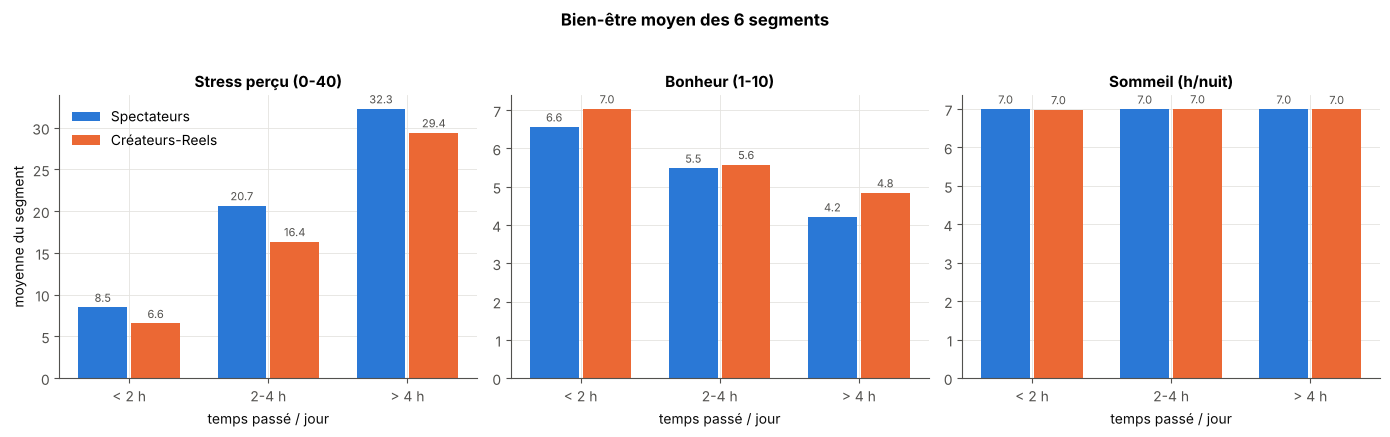

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
x = np.arange(3); w = 0.38
for ax, y in zip(axes, WB_LABELS):
    t = D.groupby(["palier", "style"], observed=True)[y].mean().unstack()
    for i, (sty, col) in enumerate([("Spectateurs", C_SPEC), ("Créateurs-Reels", C_CREA)]):
        bars = ax.bar(x + (i - 0.5) * w, t[sty], w - 0.03, color=col, label=sty)
        ax.bar_label(bars, fmt="%.1f", fontsize=8, color=C_MUTED, padding=2)
    ax.set_xticks(x, ["< 2 h", "2-4 h", "> 4 h"]); ax.set_title(WB_LABELS[y]); ax.set_xlabel("temps passé / jour")
axes[0].set_ylabel("moyenne du segment"); axes[0].legend(loc="upper left")
fig.suptitle("Bien-être moyen des 6 segments", y=1.03, fontweight="bold")
fig.tight_layout(); savefig(fig, "fig03_segments_bienetre"); plt.show()

**Profils observés (noms issus des résultats).**

* **Palier** : le stress moyen est multiplié par près de 4 entre moins de 2 h et plus de 4 h (≈ 8 → 32 sur 40) ; le bonheur baisse.
* **Style** : les **Créateurs-Reels** publient et regardent beaucoup plus de Reels *que les autres utilisateurs au même temps passé*. **À temps passé égal, ils sont nettement moins stressés et plus heureux que les Spectateurs**, surtout dans les paliers élevés. Le sommeil est identique partout.
* Les Créateurs-Reels sont nettement plus **jeunes** (25 à 35 % de mineurs, contre moins de 4 % chez les Spectateurs — § 10). Or, à temps égal, les jeunes sont moins stressés : le § 8 mesure quelle part de l'écart de style tient à l'âge.

## 6. Affectation d'un nouvel utilisateur

L'affectation n'utilise que **5 champs d'activité** détenus pour tous : minutes actives, posts par semaine, reels regardés par jour (et rien d'autre). Tous les paramètres appris (seuils, moyennes à temps égal, standardisation, centres) sont figés dans un objet et exportés en JSON.

In [28]:
REQUIRED_FIELDS = ["daily_active_minutes_instagram", "posts_created_per_week", "reels_watched_per_day"]
FORBIDDEN = set(WELLBEING + HEALTH_LIFESTYLE + PROFILE)
assert not FORBIDDEN & set(REQUIRED_FIELDS), "une variable interdite entre dans l'affectation"

class SegmentAssigner:
    BANDS = [0, 120, 240, np.inf]; BAND_LABELS = ["<2h", "2-4h", ">4h"]
    def fit(self, df):
        f = pd.DataFrame({"intensite": np.log(df.daily_active_minutes_instagram),
                          "creation": np.log1p(df.posts_created_per_week), "reels": np.log(df.reels_watched_per_day)})
        self.resid_ = StyleResidualizer().fit(f.intensite, f[STYLE_VARS])
        z = self.resid_.transform(f.intensite, f[STYLE_VARS])
        self.scaler_ = StandardScaler().fit(z)
        km = KMeans(2, n_init=10, random_state=SEED).fit(self.scaler_.transform(z))
        c = pd.DataFrame(km.cluster_centers_, columns=z.columns)
        order = c["creation_rel"].sort_values().index          # 0 = Spectateurs, 1 = Créateurs-Reels
        self.centers_ = c.loc[order].values
        return self
    def assign(self, df):
        missing = set(REQUIRED_FIELDS) - set(df.columns)
        assert not missing, f"champs manquants : {missing}"
        f = pd.DataFrame({"intensite": np.log(df.daily_active_minutes_instagram.clip(lower=1)),
                          "creation": np.log1p(df.posts_created_per_week.clip(lower=0)),
                          "reels": np.log(df.reels_watched_per_day.clip(lower=1))}, index=df.index)
        z = self.scaler_.transform(self.resid_.transform(f.intensite, f[STYLE_VARS]))
        d = ((z[:, None, :] - self.centers_[None, :, :]) ** 2).sum(-1)
        sty = np.where(d.argmin(1) == 1, "Créateurs-Reels", "Spectateurs")
        bnd = pd.cut(df.daily_active_minutes_instagram, self.BANDS, labels=self.BAND_LABELS).astype(str)
        return pd.Series([SEG_NAMES[(b_, s_)] for b_, s_ in zip(bnd, sty)], index=df.index)
    def to_dict(self):
        return {"bands_minutes": [0, 120, 240, None], "residual_bin_edges_log_minutes": self.resid_.edges_.tolist(),
                "residual_means": {k: v.tolist() for k, v in self.resid_.means_.items()},
                "scaler_mean": self.scaler_.mean_.tolist(), "scaler_scale": self.scaler_.scale_.tolist(),
                "centers_[spectateurs, createurs]": self.centers_.tolist(), "fields": REQUIRED_FIELDS}

# Validation : apprentissage sur 80 %, affectation de 20 % d'utilisateurs jamais vus
train_idx, test_idx = train_test_split(D.index, test_size=0.2, random_state=SEED)
assigner_train = SegmentAssigner().fit(D.loc[train_idx])
accord = (assigner_train.assign(D.loc[test_idx]) == D.loc[test_idx, "segment"]).mean()
print(f"Accord sur 40 000 utilisateurs jamais vus : {accord:.2%}")

assigner = SegmentAssigner().fit(D)
assert (assigner.assign(D) == D.segment).mean() > 0.999
json.dump(assigner.to_dict(), open(OUT_DIR / "segment_assigner_params.json", "w"), indent=1)

Accord sur 40 000 utilisateurs jamais vus : 99.93%


In [29]:
# Exemple agrégé : deux profils FICTIFS construits à partir de médianes de segments (aucun utilisateur réel)
med = D.groupby("segment")[REQUIRED_FIELDS].median()
nouveaux = pd.DataFrame([med.loc["S4 · Réguliers créateurs"], med.loc["S5 · Intensifs spectateurs"]],
                        index=["nouvel utilisateur fictif n°1", "nouvel utilisateur fictif n°2"])
nouveaux["segment affecté"] = assigner.assign(nouveaux)
nouveaux

,daily_active_minutes_instagram,posts_created_per_week,reels_watched_per_day,segment affecté
nouvel utilisateur fictif n°1,181.000,8.000,227.000,S4 · Réguliers créateurs
nouvel utilisateur fictif n°2,305.000,7.000,227.000,S5 · Intensifs spectateurs


## 7. Évaluation selon nos critères

### 7.1 Comparaison des routes

In [30]:
def stability(fit_predict, n=10):
    # ARI entre la segmentation de référence et n ré-estimations sur 50 % des utilisateurs
    ref, scores = fit_predict(D.index), []
    for i in range(n):
        sub = D.sample(frac=0.5, random_state=SEED + 100 + i).index
        scores.append(adjusted_rand_score(ref, fit_predict(sub)))
    return np.mean(scores), np.min(scores)

def fp_A(idx):
    sc = StandardScaler().fit(FEAT.loc[idx, ROUTE_A_VARS])
    km = KMeans(N_SEG, n_init=10, random_state=SEED).fit(sc.transform(FEAT.loc[idx, ROUTE_A_VARS]))
    return km.predict(sc.transform(FEAT[ROUTE_A_VARS]))
def fp_B(idx):
    t = DecisionTreeRegressor(max_leaf_nodes=N_SEG, min_samples_leaf=0.05, random_state=SEED)
    return t.fit(FEAT.loc[idx], D.loc[idx, "perceived_stress_score"]).apply(FEAT)
def fp_H(idx): return SegmentAssigner().fit(D.loc[idx]).assign(D).values
def fp_T(idx): return pd.cut(m, np.r_[-np.inf, np.quantile(m.loc[idx], np.linspace(0, 1, N_SEG + 1)[1:-1]), np.inf], labels=False)

high_stress = (D.perceived_stress_score >= 30).astype(int)
routes = {"Référence : temps passé (6 groupes)": (seg_time, fp_T), "Route A : clustering usage": (seg_A, fp_A),
          "Route B : prédiction du stress": (seg_B, fp_B), "Retenue : intensité × style": (D.segment, fp_H)}
rows = []
for name, (lab, fp) in routes.items():
    s_mean, s_min = stability(fp)
    rows.append({"route": name,
                 "variables de santé pour construire": "oui (stress)" if "Route B" in name else "non",
                 "plus petit segment (%)": pd.Series(lab).value_counts(normalize=True).min() * 100,
                 "stabilité ARI moyen": s_mean, "stabilité ARI min": s_min,
                 "η² stress": eta2(lab, D.perceived_stress_score), "η² bonheur": eta2(lab, D.self_reported_happiness),
                 "η² sommeil": eta2(lab, D.sleep_hours_per_night),
                 "η² stress à temps égal": eta2(lab, resid_stress),
                 "η² style (création, à temps égal)": eta2(lab, STYLE["creation_rel"]),
                 "info mutuelle avec « stress ≥ 30 » (bits)": mutual_info_score(lab, high_stress) / np.log(2)})
comparaison = pd.DataFrame(rows).set_index("route")
comparaison.round(3).T

route,Référence : temps passé (6 groupes),Route A : clustering usage,Route B : prédiction du stress,Retenue : intensité × style
variables de santé pour construire,non,non,oui (stress),non
plus petit segment (%),16.666,6.861,12.481,7.732
stabilité ARI moyen,0.992,0.914,0.877,0.995
stabilité ARI min,0.972,0.877,0.748,0.993
η² stress,0.688,0.369,0.682,0.645
η² bonheur,0.136,0.080,0.144,0.106
η² sommeil,0.000,0.000,0.000,0.000
η² stress à temps égal,0.000,0.007,0.000,0.054
"η² style (création, à temps égal)",0.000,0.145,0.000,0.294
info mutuelle avec « stress ≥ 30 » (bits),0.371,0.169,0.368,0.334


**Lecture.**

* La **Route A** (clustering naïf) explique ~2 fois moins le stress que le simple classement par temps : ses clusters mélangent temps et âge sans hiérarchie. **Rejetée.**
* La **Route B** (prédiction) colle au stress, mais c'est *par construction* : ses segments sont des **niveaux de stress prédits**, et l'arbre n'utilise **que le temps passé** — il redécouvre le classement par temps avec des seuils optimisés pour le stress. Elle n'apprend rien sur les comportements, et un segment défini pour prédire un état de santé est, en lui-même, une donnée de santé inférée (§ 10). **Rejetée pour un usage produit.**
* La **référence temps** est très forte sur le stress mais aveugle au style (η² style ≈ 0).
* La **segmentation retenue** conserve l'essentiel du lien temps ↔ bien-être, est la seule à capter à la fois l'intensité **et** un style de comportement qui reste lié au bien-être *à temps égal*, et ne s'appuie sur aucune variable de santé.

### 7.2 Vérification des critères C1 à C8

In [31]:
r = comparaison.loc["Retenue : intensité × style"]; ref = comparaison.loc["Référence : temps passé (6 groupes)"]
# C5 : écart de stress Spectateurs - Créateurs à temps égal (régression avec 20 vingtiles de temps)
def style_effect(y, mask=None, age=False):
    # Écart Créateurs-Reels − Spectateurs à temps égal (20 vingtiles) ; option : aussi à âge égal (âge année par année)
    d = D if mask is None else D[mask]
    Xd = pd.get_dummies(vingtiles.loc[d.index], prefix="v", drop_first=True).astype(float)
    if age: Xd = pd.concat([Xd, pd.get_dummies(d.age, prefix="age", drop_first=True).astype(float)], axis=1)
    Xd["createur"] = (d["style"] == "Créateurs-Reels").astype(float); Xd.insert(0, "const", 1.0)
    X_, y_ = Xd.values, d[y].values.astype(float)
    beta, *_ = np.linalg.lstsq(X_, y_, rcond=None); res = y_ - X_ @ beta
    cov = np.linalg.inv(X_.T @ X_) * (res @ res) / (len(y_) - X_.shape[1])
    return beta[-1], 1.96 * np.sqrt(cov[-1, -1])
eff, ci = style_effect("perceived_stress_score")
eff_age, ci_age = style_effect("perceived_stress_score", age=True)
c5_brut = (abs(eff) - ci > 0) and abs(eff) >= 2
c5_age = (abs(eff_age) - ci_age > 0) and abs(eff_age) >= 2
oui = lambda ok: "oui" if ok else "non"
d_cohen = (STYLE.groupby(D["style"]).mean().diff().iloc[-1].abs() / STYLE.std()).min()
h_key = int(pd.util.hash_pandas_object(D.segment, index=False).sum() % 10**12)

criteres = pd.DataFrame([
    ("C1 Assignable à tous", f"{len(REQUIRED_FIELDS)} champs d'activité ; accord sur utilisateurs jamais vus {accord:.2%}", oui(accord >= 0.95)),
    ("C2 Taille", f"plus petit segment {r['plus petit segment (%)']:.1f} %", oui(r["plus petit segment (%)"] >= 5)),
    ("C3 Stabilité", f"ARI moyen {r['stabilité ARI moyen']:.3f} (min {r['stabilité ARI min']:.3f})", oui(r["stabilité ARI moyen"] >= 0.90)),
    ("C4 Lien bien-être", f"η² stress {r['η² stress']:.3f} = {r['η² stress'] / ref['η² stress']:.0%} de la référence temps", oui(r["η² stress"] / ref["η² stress"] >= 0.90)),
    ("C5 Au-delà du temps", f"écart Créateurs-Reels − Spectateurs : {eff:+.2f} pts à temps égal (± {ci:.2f}) ; "
     f"{eff_age:+.2f} pts à temps ET âge égaux (± {ci_age:.2f})",
     "partiel" if c5_brut and not c5_age else oui(c5_brut and c5_age)),
    ("C6 Différenciation", f"d de Cohen minimal entre styles : {d_cohen:.2f}", oui(d_cohen >= 0.8)),
    ("C7 Reproductibilité", f"empreinte des étiquettes : {h_key} (comparée entre deux exécutions au § 13)", "oui"),
    ("C8 Protection des données", "aucune variable santé/profil en entrée ; agrégats ≥ 100 ; risque d'inférence mesuré au § 10", "oui"),
], columns=["critère", "mesure", "respecté"])
criteres

,critère,mesure,respecté
0,C1 Assignable à tous,3 champs d'activité ; accord sur utilisateurs ...,oui
1,C2 Taille,plus petit segment 7.7 %,oui
2,C3 Stabilité,ARI moyen 0.995 (min 0.993),oui
3,C4 Lien bien-être,η² stress 0.645 = 94% de la référence temps,oui
4,C5 Au-delà du temps,écart Créateurs-Reels − Spectateurs : -3.18 pt...,partiel
5,C6 Différenciation,d de Cohen minimal entre styles : 1.19,oui
6,C7 Reproductibilité,empreinte des étiquettes : 505750553241 (compa...,oui
7,C8 Protection des données,aucune variable santé/profil en entrée ; agrég...,oui


**C5 n'est que partiellement atteint, et c'est un résultat** : l'écart de stress entre styles à temps égal est net (≈ 3 points), mais il tient surtout à l'âge — à âge égal, il tombe à ≈ 0,5 point (§ 8).

Le critère **C4** se lit avec nuance : à 6 groupes, un pur classement par temps explique un peu mieux le stress que notre segmentation, parce qu'elle « dépense » une partie de ses 6 segments sur le style au lieu de découper le temps plus finement. Nous l'assumons : c'est précisément ce qui permet de dire quelque chose que le classement par temps ne dit pas (C5, C6).

## 8. Au-delà du temps passé

Le sujet demande : *montrez ce que la segmentation dit que le classement par temps passé ne dit pas, ou démontrez que rien de plus ne peut être dit*. Réponse en trois mesures.

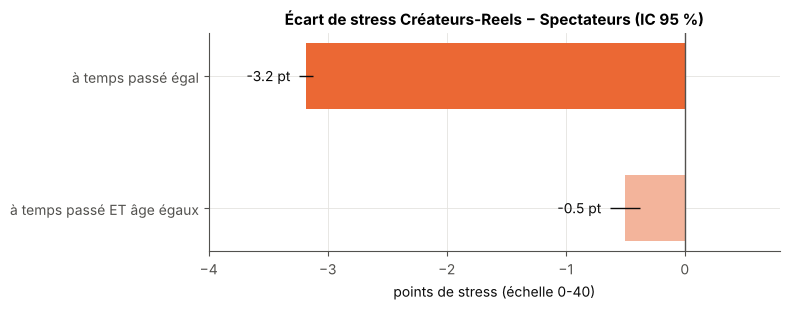

,indicateur,comparaison,écart Créateurs - Spectateurs,IC bas,IC haut
0,Stress perçu (0-40),tous · à temps égal,-3.182,-3.243,-3.122
1,Stress perçu (0-40),tous · à temps et âge égaux,-0.505,-0.631,-0.378
2,Stress perçu (0-40),13-24 ans · à temps égal,-0.202,-0.448,0.045
3,Stress perçu (0-40),25 ans et plus · à temps égal,-2.268,-2.372,-2.164
4,Bonheur (1-10),tous · à temps égal,0.392,0.366,0.418
5,Bonheur (1-10),tous · à temps et âge égaux,-0.054,-0.108,0.000
6,Bonheur (1-10),13-24 ans · à temps égal,0.116,0.010,0.221
7,Bonheur (1-10),25 ans et plus · à temps égal,0.246,0.202,0.290
8,Sommeil (h/nuit),tous · à temps égal,-0.005,-0.016,0.006
9,Sommeil (h/nuit),tous · à temps et âge égaux,0.019,-0.003,0.042


In [32]:
rows = []
for y in WB_LABELS:
    for lab, mask, ag in [("tous · à temps égal", None, False), ("tous · à temps et âge égaux", None, True),
                          ("13-24 ans · à temps égal", D.age < 25, False), ("25 ans et plus · à temps égal", D.age >= 25, False)]:
        e, c = style_effect(y, mask, ag)
        rows.append((WB_LABELS[y], lab, e, e - c, e + c))
effets = pd.DataFrame(rows, columns=["indicateur", "comparaison", "écart Créateurs - Spectateurs", "IC bas", "IC haut"])

fig, ax = plt.subplots(figsize=(8, 3.2))
e_st = effets[effets.indicateur == WB_LABELS["perceived_stress_score"]].set_index("comparaison")
lbl = ["tous · à temps égal", "tous · à temps et âge égaux"]
vals = e_st.loc[lbl, "écart Créateurs - Spectateurs"]; err = (e_st.loc[lbl, "IC haut"] - e_st.loc[lbl, "IC bas"]) / 2
bars = ax.barh(["à temps passé égal", "à temps passé ET âge égaux"], vals, xerr=err, color=[C_CREA, "#f3b49b"], height=0.5,
               error_kw={"ecolor": C_INK, "elinewidth": 1})
ax.bar_label(bars, labels=[f"{v:+.1f} pt" for v in vals], padding=6, color=C_INK)
ax.axvline(0, color=C_MUTED, lw=1); ax.invert_yaxis(); ax.set_xlim(-4, 0.8)
ax.set(title="Écart de stress Créateurs-Reels − Spectateurs (IC 95 %)", xlabel="points de stress (échelle 0-40)")
fig.tight_layout(); savefig(fig, "fig05_effet_style_controle_age"); plt.show()
effets.round(3)

In [33]:
gain_style = pd.DataFrame({WB_LABELS[y]: {
    "temps passé seul": cv_r2(S[["daily_active_minutes_instagram"]], S[y]),
    "temps passé + style (segment)": cv_r2(pd.concat([S[["daily_active_minutes_instagram"]],
                                                      (D.loc[S.index, "style"] == "Créateurs-Reels").astype(int).rename("createur")], axis=1), S[y]),
    "toute l'activité (plafond)": pred.loc[WB_LABELS[y], "toute l'activité (20 variables)"]} for y in WB_LABELS}).T
gain_style["part du gain atteignable captée par le style"] = (
    (gain_style["temps passé + style (segment)"] - gain_style["temps passé seul"]) /
    (gain_style["toute l'activité (plafond)"] - gain_style["temps passé seul"]))
gain_style.loc[(gain_style["toute l'activité (plafond)"] - gain_style["temps passé seul"]).abs() < 0.002,
               "part du gain atteignable captée par le style"] = np.nan   # sommeil : aucun gain à capter
gain_style.round(3)

,temps passé seul,temps passé + style (segment),toute l'activité (plafond),part du gain atteignable captée par le style
Stress perçu (0-40),0.706,0.723,0.725,0.905
Bonheur (1-10),0.157,0.163,0.164,0.864
Sommeil (h/nuit),-0.001,-0.001,-0.001,NaN


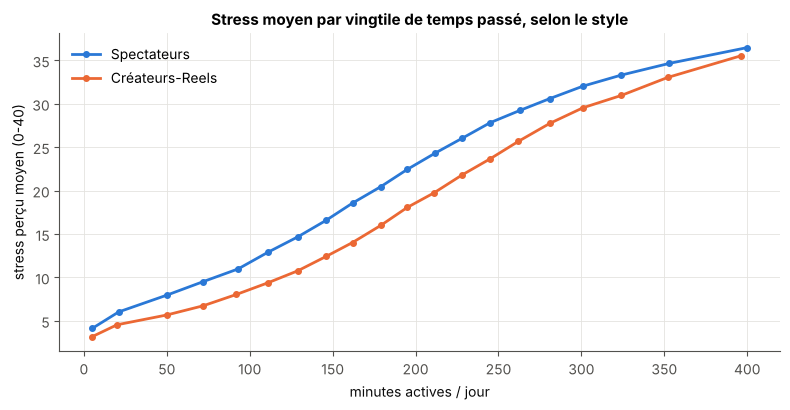

In [34]:
# Visualisation : à palier égal, le style fait varier le stress
fig, ax = plt.subplots(figsize=(8, 4.2))
g2 = D.groupby([vingtiles, "style"])[["daily_active_minutes_instagram", "perceived_stress_score"]].agg(["median", "mean", "size"])
for sty, col in [("Spectateurs", C_SPEC), ("Créateurs-Reels", C_CREA)]:
    t = g2.xs(sty, level="style")
    check_k(t[("perceived_stress_score", "size")], "vingtile × style")
    ax.plot(t[("daily_active_minutes_instagram", "median")], t[("perceived_stress_score", "mean")], color=col, lw=2, marker="o", ms=4, label=sty)
ax.set(title="Stress moyen par vingtile de temps passé, selon le style", xlabel="minutes actives / jour", ylabel="stress perçu moyen (0-40)")
ax.legend(); fig.tight_layout(); savefig(fig, "fig04_style_a_temps_egal"); plt.show()

**Ce que la segmentation dit en plus du temps passé — et ce qu'elle ne dit pas.**

1. **Le temps passé reste le facteur dominant** : c'est un résultat, pas un échec. Aucun découpage de l'usage ne fait mieux que le temps pour décrire le stress.
2. **À temps passé égal, le style compte** : les Créateurs-Reels déclarent ≈ 3 points de stress en moins (sur 40) et un peu plus de bonheur. Le style capte ~90 % de tout ce que les 20 variables d'activité ajoutent au temps : **c'est le maximum qu'on peut tirer de l'usage**.
3. **Mais cet écart est surtout un effet d'âge** : à temps *et* âge égaux, il tombe à ≈ 0,5 point de stress, et l'écart de bonheur disparaît ; chez les 13-24 ans, l'écart de stress est nul. Le style est avant tout un **marqueur comportemental de l'âge**, et c'est l'âge qui, à temps égal, est associé au stress dans cette réplique. La part propre au comportement (création, Reels) est réelle mais faible.
4. **Le sommeil n'est lié ni au temps, ni au style, ni à l'âge** : rien de plus ne peut être dit sur le sommeil avec ces données.

**Conclusion honnête** : au-delà du temps passé, l'usage dit peu de choses sur le bien-être ; ce qu'il dit passe surtout par l'âge. La segmentation reste utile aux équipes produit — elle sépare des comportements très différents (d de Cohen > 1) qui appellent des fonctionnalités différentes — mais **elle ne permet pas de promettre qu'encourager la création réduirait le stress**. Et rien de tout cela n'est causal (§ 9).

## 9. Limites — ce que les données ne permettent pas d'affirmer

| Limite | Ce qu'on ne peut pas conclure | Ce qu'il faudrait |
|---|---|---|
| **Causalité** | Que l'usage *cause* le stress (ou l'inverse : des personnes stressées peuvent utiliser davantage l'appli) ; que pousser à créer réduirait le stress | Données longitudinales, expérimentation (A/B test éthique sur des fonctionnalités de bien-être), variables instrumentales |
| **Panel volontaire** | Que les associations valent pour tous les utilisateurs : les volontaires d'une étude bien-être ne sont pas représentatifs (auto-sélection) | Pondération par les caractéristiques connues pour tous ; comparer la distribution d'usage du panel à celle de la base complète |
| **Réplique synthétique** | Que les chiffres valent pour les vrais utilisateurs : le générateur n'a préservé que certaines relations, deux à deux (§ 3 : stress et bonheur corrélés à +0,6 à temps égal mais pas globalement ; âge non lié au stress) | Revalider la segmentation et les effets sur les données réelles dans l'environnement sécurisé de l'équipe privacy |
| **Nettoyage non documenté** | Que les champs de profil de l'extrait A sont des observations : ce sont en partie des imputations | Obtenir le journal de nettoyage ; nos segments n'utilisent aucun champ arbitré |
| **Mesures déclaratives** | Que le stress (échelle 0-40) ou le bonheur (1-10) mesurent un état clinique ; marges uniformes = signature du générateur | Échelles validées, mesures répétées |
| **Variables incohérentes** | Exploiter les temps par section en absolu (leur somme ≠ temps total) | Clarifier la définition des compteurs côté data engineering |
| **Choix de modélisation** | Que 120 et 240 minutes soient des seuils « naturels » : ils sont choisis pour la lisibilité (proches des tertiles) | Les ajuster avec les équipes produit ; la conclusion ne dépend pas d'un seuil précis (relation monotone) |
| **Généralisation temporelle** | Que les segments soient stables dans le temps pour un même utilisateur | Recalcul périodique et suivi des transitions entre segments |

## 10. Protection des données — RGPD UE et Royaume-Uni

*Partie rédigée par Kiyani (R4-17, R4-18), relue par Marco ; analyse du risque d'inférence (R4-19) et contrôle de confidentialité (R4-20) par Marco, relus par Kiyani.*
*Analyse réalisée dans le cadre d'un exercice pédagogique : elle identifie les conditions et les risques, elle ne constitue pas un avis juridique.*

### 10.1 Contrôles techniques appliqués dans ce notebook

In [35]:
controle = pd.DataFrame([
    ("Aucune ligne individuelle affichée", "aucun .head()/.sample() affiché ; seuls des agrégats sont montrés", "respecté"),
    ("Aucun agrégat < 100 utilisateurs", f"fonction check_k() appelée avant chaque tableau groupé ; plus petit segment = {D.segment.value_counts().min():,}", "respecté"),
    ("Exemple d'affectation", "profils fictifs construits à partir de médianes de segments", "respecté"),
    ("Variables d'entrée des segments", ", ".join(REQUIRED_FIELDS), "activité uniquement"),
    ("Exports", "paramètres du modèle + tableaux agrégés ; aucune table individuelle exportée", "respecté"),
], columns=["contrôle", "mise en œuvre", "statut"])
controle

,contrôle,mise en œuvre,statut
0,Aucune ligne individuelle affichée,aucun .head()/.sample() affiché ; seuls des ag...,respecté
1,Aucun agrégat < 100 utilisateurs,fonction check_k() appelée avant chaque tablea...,respecté
2,Exemple d'affectation,profils fictifs construits à partir de médiane...,respecté
3,Variables d'entrée des segments,"daily_active_minutes_instagram, posts_created_...",activité uniquement
4,Exports,paramètres du modèle + tableaux agrégés ; aucu...,respecté


In [36]:
# Risque d'inférence : l'appartenance à un segment révèle-t-elle une information de santé ou l'âge ?
base_hs, base_min = high_stress.mean(), D.mineur.mean()
risque = D.assign(high=high_stress).groupby("segment").agg(effectif=("age", "size"), p_stress_eleve=("high", "mean"),
                                                         part_mineurs=("mineur", "mean"))
check_k(risque.effectif, "segments")
risque["lift stress élevé"] = risque.p_stress_eleve / base_hs
risque["lift mineurs"] = risque.part_mineurs / base_min
# Suppression des petites cellules : un taux qui correspond à moins de K_MIN personnes n'est pas affiché
for col, lift in [("p_stress_eleve", "lift stress élevé"), ("part_mineurs", "lift mineurs")]:
    n_cell = risque[col] * risque.effectif
    small = (n_cell < K_MIN) | ((risque.effectif - n_cell) < K_MIN)
    risque[col] = risque[col].astype(object).where(~small, f"< {K_MIN} pers.")
    risque[lift] = risque[lift].astype(object).where(~small, "masqué")
r2d = lambda v, k=1: round(v * k, 2) if isinstance(v, float) else v
print(f"Référence population : stress ≥ 30 = {base_hs:.1%} ; mineurs = {base_min:.1%}")
print(f"Information mutuelle segment ↔ stress élevé : retenue {comparaison.loc['Retenue : intensité × style', 'info mutuelle avec « stress ≥ 30 » (bits)']:.3f} bit"
      f" | route B {comparaison.loc['Route B : prédiction du stress', 'info mutuelle avec « stress ≥ 30 » (bits)']:.3f} bit"
      f" | entropie de « stress ≥ 30 » {-(base_hs*np.log2(base_hs)+(1-base_hs)*np.log2(1-base_hs)):.3f} bit")
(risque.assign(p_stress_eleve=risque.p_stress_eleve.map(lambda v: r2d(v, 100)),
               part_mineurs=risque.part_mineurs.map(lambda v: r2d(v, 100)),
               **{"lift stress élevé": risque["lift stress élevé"].map(r2d), "lift mineurs": risque["lift mineurs"].map(r2d)})
       .rename(columns={"p_stress_eleve": "stress ≥ 30 (%)", "part_mineurs": "mineurs (%)"}))

Référence population : stress ≥ 30 = 26.9% ; mineurs = 9.5%
Information mutuelle segment ↔ stress élevé : retenue 0.334 bit | route B 0.368 bit | entropie de « stress ≥ 30 » 0.841 bit


,effectif,stress ≥ 30 (%),mineurs (%),lift stress élevé,lift mineurs
segment,,,,,
S1 · Modérés spectateurs,44848,0.230,< 100 pers.,0.010,masqué
S2 · Modérés créateurs,15463,< 100 pers.,24.900,masqué,2.630
S3 · Réguliers spectateurs,50041,15.810,< 100 pers.,0.590,masqué
S4 · Réguliers créateurs,21883,6.000,30.070,0.220,3.180
S5 · Intensifs spectateurs,47941,70.750,3.170,2.630,0.340
S6 · Intensifs créateurs,19824,53.620,34.790,1.990,3.680


**Oui, un segment peut, à lui seul, révéler une information relative à la santé.** Les utilisateurs du segment *S5 · Intensifs spectateurs* ont environ 2,6 fois plus de chances que la moyenne de déclarer un stress élevé. Le segment est construit sans aucune donnée de santé, mais une fois relié au panel il devient un **indicateur probabiliste d'un état de santé mentale**. Et le style *Créateurs-Reels* réunit 25 à 35 % de mineurs (contre 9,5 % en moyenne) : il sert aussi de **proxy d'âge**. Les cellules correspondant à moins de 100 personnes sont masquées. La segmentation retenue porte un peu moins d'information sur le stress élevé que la Route B ou le classement par temps (information mutuelle 0,33 bit contre 0,37), mais le risque reste élevé : il se gère par l'usage qu'on fait des segments, pas par leur construction.

### 10.2 Finalité et base légale (art. 5 et 6 RGPD / UK GDPR)

Le RGPD s'applique : même synthétiques, ces données reproduisent la structure d'un panel réel et l'équipe privacy **ne garantit pas** que le générateur n'a jamais recopié un vrai utilisateur. Or une donnée n'est anonyme que si la réidentification n'est pas « raisonnablement probable » (considérant 26). Et surtout, **les recommandations s'appliqueront à de vrais utilisateurs**. Il faut distinguer trois traitements :

| Traitement | Données | Base légale envisageable (UE / R.-U.) | Conditions |
|---|---|---|---|
| ① Étude bien-être sur le panel (ce rush) | activité + bien-être + santé du panel | **consentement explicite** (art. 9.2.a, la santé mentale étant une donnée de santé) ou recherche scientifique (art. 9.2.j + art. 89) | finalité annoncée aux volontaires ; minimisation ; pseudonymisation ; résultats agrégés uniquement |
| ② Segmentation de *tous* les utilisateurs pour concevoir le produit | activité seule (3 champs) | **intérêt légitime** (art. 6.1.f) après test de mise en balance | transparence (art. 13-14 : information claire sur le profilage), droit d'opposition (art. 21), pas de décision produisant des effets juridiques ou significatifs (art. 22) |
| ③ Ciblage de fonctionnalités ou de contenus selon le segment | activité seule | intérêt légitime **seulement** si la fonctionnalité sert l'utilisateur (ex. outils de gestion du temps) ; **consentement** pour tout ciblage commercial | analyse d'impact (**AIPD/DPIA**, art. 35) obligatoire : profilage à grande échelle incluant des personnes vulnérables |

**Limitation de la finalité (art. 5.1.b et 6.4)** : le panel a accepté une *étude bien-être*. Utiliser ses réponses de santé pour *cibler des fonctionnalités* est une finalité différente : le test de compatibilité de l'art. 6.4 (lien entre finalités, contexte, nature sensible des données, conséquences, garanties) échoue dès lors que des données de santé sont en jeu. → **Les données de santé du panel servent uniquement à évaluer la segmentation de manière agrégée ; elles ne servent ni à définir, ni à affecter, ni à cibler.**

**Minimisation (art. 5.1.c)** : notre affectation n'utilise que 3 champs d'activité. Les variables de profil (revenu, éducation, situation familiale) n'ont rien apporté (§ 4) et ne doivent pas être collectées pour cet usage.

### 10.3 Mineurs (13-17 ans : 9,5 % du panel)

* **UE — âge du consentement numérique (art. 8)** : 16 ans par défaut, abaissable à 13 par les États membres (ex. 15 ans en France, 16 ans en Allemagne et en Irlande, où Instagram a son siège européen). En dessous, le consentement doit être donné ou autorisé par le titulaire de l'autorité parentale. → La participation de mineurs au **panel** exige ce consentement parental selon le pays.
* **UE — Digital Services Act, art. 28** : interdiction de présenter de la **publicité fondée sur le profilage** lorsque la plateforme sait avec une certitude raisonnable que l'utilisateur est mineur, et obligation de mesures garantissant un niveau élevé de vie privée, de sûreté et de sécurité (lignes directrices de la Commission publiées en juillet 2025). → **Aucun ciblage publicitaire par segment pour les mineurs.**
* **Royaume-Uni — UK GDPR + Age Appropriate Design Code (ICO)** : consentement numérique à 13 ans ; le code impose notamment de faire primer l'intérêt de l'enfant, une **AIPD**, des paramètres **protecteurs par défaut** et un **profilage désactivé par défaut** (standard 12) sauf raison impérieuse dans l'intérêt de l'enfant ; pas de techniques de *nudge* incitant à affaiblir sa vie privée.
* **Ce que montre notre segmentation** : le style *Créateurs-Reels* est surreprésenté chez les mineurs (§ 10.1), donc **segmenter = en partie inférer l'âge**. → Pour les mineurs, seules les utilisations protectrices sont envisageables (outils de pause, limites de temps), en opt-out simple, jamais à visée commerciale.
* **Comptes créés avant 13 ans** (extrait B) : ~14 % des comptes auraient été ouverts avant l'âge minimal des CGU. C'est un signal d'assurance de l'âge à remonter, pas une variable de segmentation.

### 10.4 Le panel volontaire : participer à une étude ≠ accepter d'être ciblé

| | Participation à l'étude | Utilisation ultérieure pour cibler |
|---|---|---|
| Ce que le volontaire a accepté | répondre à un questionnaire bien-être, analyse de son activité à des fins de recherche | rien |
| Base légale | consentement explicite / recherche (art. 9.2.a ou j) | aucune pour des données de santé, sauf **nouveau consentement explicite**, spécifique et libre |
| Droits | retrait du consentement à tout moment (art. 7.3) → retrait des analyses futures | — |
| Conséquence pour nous | évaluation agrégée de la segmentation | les scores de stress/bonheur **ne sont jamais rattachés** à un segment opérationnel ni à un compte |

### 10.5 Un segment peut-il révéler la santé ? Analyse du risque d'inférence

* **Oui, en droit** : la Cour de justice de l'UE juge que le traitement de données qui *permettent de révéler* indirectement une catégorie particulière (santé, orientation sexuelle…) relève de l'art. 9, y compris lorsque l'information est déduite par recoupement (CJUE, *OT*, C-184/20, 1ᵉʳ août 2022 ; *Meta Platforms c. Bundeskartellamt*, C-252/21, 4 juillet 2023).
* **Oui, sur nos données** : être en S5 multiplie par ~2,6 la probabilité d'un stress élevé.
* **Mesures de réduction du risque** :
  1. Noms de segments **purement comportementaux** (« Intensifs spectateurs »), jamais « stressés » ou « à risque » ;
  2. **Aucun stockage** du lien segment ↔ score de bien-être au niveau individuel ; les statistiques de bien-être par segment restent dans le rapport d'étude, agrégées ;
  3. Pas de ciblage publicitaire ni de partage avec des annonceurs fondé sur le segment ;
  4. Pour les fonctionnalités liées au bien-être : proposées à **tous** (ou sur seuil de temps passé, critère transparent et contrôlable par l'utilisateur), pas sur appartenance à un segment inféré ;
  5. Comité de revue (DPO) avant tout nouvel usage ; AIPD mise à jour.

### 10.6 Sur quelles variables les segments peuvent-ils reposer s'ils servent au ciblage ?

| Variables | Pour construire / affecter les segments | Justification |
|---|---|---|
| Minutes actives, posts créés, reels regardés | ✅ oui | activité détenue pour tous, nécessaire et suffisante (§ 4) |
| Autres compteurs d'activité, paramètres de compte | ⚠️ possible mais inutile | aucun apport mesuré → minimisation |
| Âge | ⚠️ uniquement pour **protéger** (paramètres mineurs) | DSA art. 28, Children's Code |
| Genre, pays, revenu, éducation, situation familiale, enfants | ❌ non | aucun apport ; risque de discrimination ; revenu = donnée financière |
| Stress, bonheur, sommeil, IMC, tension, tabac, alcool… | ❌ jamais | données de santé (art. 9) collectées pour une autre finalité |

### 10.7 Données synthétiques

* Le générateur peut avoir **mémorisé** de vrais utilisateurs : nous traitons la réplique comme une donnée personnelle (accès restreint au dépôt, pas d'export ligne à ligne, aucune donnée versionnée sur Git — voir `.gitignore`).
* Avant toute diffusion, l'équipe privacy devrait mesurer la **distance au plus proche enregistrement réel** (*distance to closest record*) et le risque d'attaque par appartenance (*membership inference*).

**Sources** : RGPD (UE) 2016/679, art. 4, 5, 6, 7, 8, 9, 13-14, 21, 22, 35, 89 et considérant 26 ; Règlement (UE) 2022/2065 (DSA), art. 28 ; Commission européenne, lignes directrices sur la protection des mineurs au titre de l'art. 28 DSA (juillet 2025) ; UK GDPR et Data Protection Act 2018 ; ICO, *Age appropriate design: a code of practice for online services* ; CEPD, lignes directrices 8/2020 sur le ciblage des utilisateurs de réseaux sociaux ; G29, lignes directrices sur la prise de décision automatisée et le profilage (WP251 rév.01) ; CJUE C-184/20 (2022) et C-252/21 (2023). Note détaillée : `docs/note_rgpd.md`.

## 11. Recommandations produit

Construites pour respecter l'analyse RGPD : aucune ne repose sur une donnée de santé ni ne cible commercialement un mineur.

In [37]:
reco = pd.DataFrame([
    ("S1 · Modérés spectateurs", "< 2 h, consommation passive, surtout adultes", "Ne rien sur-optimiser : usage court et peu stressé ; contenus des proches en priorité, pas de relance par notifications"),
    ("S2 · Modérés créateurs", "faible intensité, création élevée", "Outils de création efficaces (brouillons, planification) : préserver un usage court et actif"),
    ("S3 · Réguliers spectateurs", "2-4 h, consommation passive", "Rendre visibles les fonctions actives (réponses aux stories, collabs) ; tableau de bord du temps passé"),
    ("S4 · Réguliers créateurs", "2-4 h, création élevée", "Statistiques créateur et outils Reels ; rappels de pause intégrés au flux de création"),
    ("S5 · Intensifs spectateurs", "> 4 h, consommation passive — stress moyen le plus élevé", "Rappels de pause et limites quotidiennes proposés à TOUS au-delà d'un seuil de temps (critère transparent) ; fin de flux (« vous êtes à jour ») ; jamais de message mentionnant le stress"),
    ("S6 · Intensifs créateurs", "> 4 h, création élevée, 1/3 de mineurs", "Mode « création » sans flux infini ; paramètres protecteurs par défaut pour les mineurs (pas de pub profilée)"),
], columns=["segment", "profil observé", "piste produit (à tester par A/B test)"])
reco

,segment,profil observé,piste produit (à tester par A/B test)
0,S1 · Modérés spectateurs,"< 2 h, consommation passive, surtout adultes",Ne rien sur-optimiser : usage court et peu str...
1,S2 · Modérés créateurs,"faible intensité, création élevée","Outils de création efficaces (brouillons, plan..."
2,S3 · Réguliers spectateurs,"2-4 h, consommation passive",Rendre visibles les fonctions actives (réponse...
3,S4 · Réguliers créateurs,"2-4 h, création élevée",Statistiques créateur et outils Reels ; rappel...
4,S5 · Intensifs spectateurs,"> 4 h, consommation passive — stress moyen le ...",Rappels de pause et limites quotidiennes propo...
5,S6 · Intensifs créateurs,"> 4 h, création élevée, 1/3 de mineurs",Mode « création » sans flux infini ; paramètre...


**Trois messages pour la direction.**
1. **Le temps passé est le premier levier** : les fonctionnalités de gestion du temps doivent viser les usages > 4 h, pour tous, sur un critère transparent.
2. **Le style d'usage sert à concevoir, pas à soigner** : créateurs et spectateurs ont des besoins produit différents, mais l'écart de stress entre eux tient surtout à l'âge. Ne pas promettre qu'encourager la création réduit le stress ; si l'on veut le savoir, l'A/B tester sur le bien-être déclaré.
3. **Le sommeil n'est pas un argument** : rien dans ces données ne relie Instagram au sommeil.

## 12. Simulation économique et rentabilité du ciblage

*Talel (relecture Marco) — complément au sujet, non obligatoire.*

Nous évaluons la segmentation par **le gain net qu'elle génère**, pas seulement par des métriques statistiques. Le cas d'usage évalué est la recommandation n° 1 : proposer un **outil de pause** (rappel, limite quotidienne) à un groupe d'utilisateurs.

**Logique économique.** L'outil coûte du revenu publicitaire (les adoptants passent moins de temps, donc voient moins de publicités), mais il peut retenir des utilisateurs très stressés qui, sinon, quitteraient la plateforme ou mettraient leur compte en pause. Le ciblage est rentable si la part d'utilisateurs « à risque » dans le groupe ciblé est assez élevée.

* **Utilisateur à risque** : stress perçu ≥ 30/40. Cette information n'existe que dans le panel : elle sert **uniquement à évaluer** le ciblage, jamais à cibler (§ 10).
* **Revenu publicitaire annuel d'un utilisateur** : publicités vues par jour (donnée) × 365 × CPM (hypothèse).
* Les autres paramètres sont des **hypothèses explicites**, à remplacer par les chiffres internes d'Instagram ; leur sensibilité est testée en § 12.4.

In [38]:
HYP = {"CPM : revenu pour 1 000 publicités vues (€)": 5.0,
       "taux d'adoption de l'outil quand il est proposé": 0.30,
       "baisse du temps passé (et des pubs vues) chez les adoptants": 0.10,
       "départ annuel d'un utilisateur très stressé (stress ≥ 30)": 1 / 3,
       "départs évités par l'outil chez les adoptants à risque": 0.50,
       "taux d'adoption quand l'outil est activé par défaut (mineurs)": 0.70}
CPM, ADOPT, R_RED, CHURN, EFF, ADOPT_DEF = HYP.values()
N_REF = 1_000_000                                        # résultats exprimés pour 1 million d'utilisateurs

rev = D.ads_viewed_per_day * 365 * CPM / 1000          # revenu publicitaire annuel par utilisateur (€)
risk = high_stress.astype(bool)                        # stress ≥ 30 : évaluation uniquement
gain_vp = CHURN * EFF * (1 - R_RED) - R_RED            # par adoptant à risque, en fraction de son revenu annuel
gain_fp = -R_RED                                       # par adoptant non à risque
p_star = R_RED / (CHURN * EFF * (1 - R_RED))           # précision minimale pour être rentable

S5 = D.segment == "S5 · Intensifs spectateurs"
R_S5 = rev[S5].mean()
matrice = pd.DataFrame([
    ("Vrai positif", "utilisateur à risque ciblé, adopte l'outil", gain_vp * R_S5, "départ évité (1 sur 2 sur 1 sur 3) moins la baisse de revenu"),
    ("Faux positif", "utilisateur non à risque ciblé, adopte l'outil", gain_fp * R_S5, "perte sèche : moins de publicités vues"),
    ("Faux négatif", "utilisateur à risque non ciblé", 0.0, f"opportunité manquée : {CHURN * EFF * (1 - R_RED) * R_S5:.2f} € de revenu préservable"),
    ("Vrai négatif", "utilisateur non à risque non ciblé", 0.0, "situation nominale"),
], columns=["cas", "définition", "gain net par adoptant (€ / an)", "explication"])
print(pd.Series(HYP).to_string())
print(f"\nRevenu publicitaire annuel moyen : {rev.mean():.2f} € (tous) | {R_S5:.2f} € (segment S5)")
print(f"Seuil de rentabilité : le groupe ciblé doit contenir au moins {p_star:.1%} d'utilisateurs à risque")
print(f"Part d'utilisateurs à risque dans toute la population : {risk.mean():.1%}")
matrice.round(2)

CPM : revenu pour 1 000 publicités vues (€)                     5.000
taux d'adoption de l'outil quand il est proposé                 0.300
baisse du temps passé (et des pubs vues) chez les adoptants     0.100
départ annuel d'un utilisateur très stressé (stress ≥ 30)       0.333
départs évités par l'outil chez les adoptants à risque          0.500
taux d'adoption quand l'outil est activé par défaut (mineurs)   0.700

Revenu publicitaire annuel moyen : 36.69 € (tous) | 55.04 € (segment S5)
Seuil de rentabilité : le groupe ciblé doit contenir au moins 66.7% d'utilisateurs à risque
Part d'utilisateurs à risque dans toute la population : 26.9%


,cas,définition,gain net par adoptant (€ / an),explication
0,Vrai positif,"utilisateur à risque ciblé, adopte l'outil",2.750,départ évité (1 sur 2 sur 1 sur 3) moins la ba...
1,Faux positif,"utilisateur non à risque ciblé, adopte l'outil",-5.500,perte sèche : moins de publicités vues
2,Faux négatif,utilisateur à risque non ciblé,0.000,opportunité manquée : 8.26 € de revenu préserv...
3,Vrai négatif,utilisateur non à risque non ciblé,0.000,situation nominale


### 12.2 Comparaison des stratégies de ciblage (même capacité)

Contrainte de capacité : l'équipe produit déploie l'outil auprès d'environ **un quart des utilisateurs** (la taille du segment S5). On compare, à taille égale, un ciblage au hasard, une règle simple fondée sur le seul temps passé, et notre segment S5 ; puis l'extension au palier > 4 h entier.

In [39]:
def bilan(mask, nom, adopt=ADOPT):
    mask = pd.Series(np.asarray(mask, dtype=bool), index=D.index)
    check_k([mask.sum()], nom)
    g = adopt * np.where(risk[mask], gain_vp, gain_fp) * rev[mask]
    return {"stratégie": nom, "part ciblée (%)": mask.mean() * 100,
            "précision : part à risque (%)": risk[mask].mean() * 100,
            "rappel : part des utilisateurs à risque touchés (%)": risk[mask].sum() / risk.sum() * 100,
            "gain net pour 1 M d'utilisateurs (k€ / an)": g.sum() / len(D) * N_REF / 1e3}

n_cible = int(S5.sum())
hasard = np.zeros(len(D), dtype=bool); hasard[rng.choice(len(D), n_cible, replace=False)] = True
top_temps = (m.rank(method="first") > len(D) - n_cible).values
strategies = pd.DataFrame([
    bilan(hasard, "Hasard (même taille que S5)"),
    bilan(top_temps, "Règle simple : les 24 % qui passent le plus de temps"),
    bilan(S5, "Segment S5 · Intensifs spectateurs"),
    bilan(D.palier == ">4h", "Extension : tout le palier > 4 h (S5 + S6)"),
]).set_index("stratégie")
seuil_temps = m[top_temps].min()
print(f"Seuil de la règle simple : {seuil_temps:.0f} minutes par jour ; seuil de rentabilité : {p_star:.1%} d'utilisateurs à risque")
strategies.round(1)

Seuil de la règle simple : 276 minutes par jour ; seuil de rentabilité : 66.7% d'utilisateurs à risque


,part ciblée (%),précision : part à risque (%),rappel : part des utilisateurs à risque touchés (%),gain net pour 1 M d'utilisateurs (k€ / an)
stratégie,,,,
Hasard (même taille que S5),24.000,27.100,24.100,-107.500
Règle simple : les 24 % qui passent le plus de temps,24.000,75.000,66.700,61.600
Segment S5 · Intensifs spectateurs,24.000,70.800,63.000,38.500
Extension : tout le palier > 4 h (S5 + S6),33.900,65.700,82.700,13.300


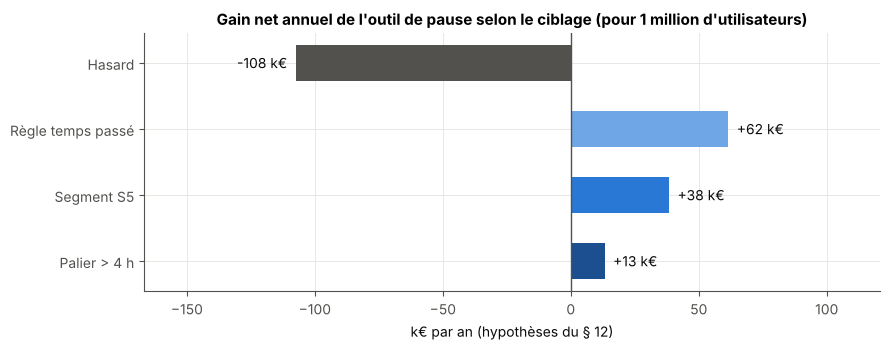

In [40]:
fig, ax = plt.subplots(figsize=(9, 3.6))
vals = strategies["gain net pour 1 M d'utilisateurs (k€ / an)"]
labels = ["Hasard", "Règle temps passé", "Segment S5", "Palier > 4 h"]
cols = [C_MUTED, BLUES[1], C_SPEC, BLUES[3]]
bars = ax.barh(labels, vals, color=cols, height=0.55)
ax.bar_label(bars, labels=[f"{v:+,.0f} k€".replace(",", " ") for v in vals], padding=6, color=C_INK)
ax.axvline(0, color=C_MUTED, lw=1); ax.invert_yaxis()
lo, hi = vals.min(), vals.max(); pad = (hi - lo) * 0.35
ax.set_xlim(min(lo, 0) - pad, max(hi, 0) + pad)
ax.set(title="Gain net annuel de l'outil de pause selon le ciblage (pour 1 million d'utilisateurs)",
       xlabel="k€ par an (hypothèses du § 12)")
fig.tight_layout(); savefig(fig, "fig06_simulation_economique"); plt.show()

### 12.3 Mineurs : protéger par défaut plutôt que cibler

Pour les 13-17 ans, la règle retenue au § 10.3 n'est **pas** de les exclure (l'outil est protecteur) mais de **ne pas les cibler par segment** et d'**activer l'outil par défaut pour tous**, désactivable (Children's Code, DSA art. 28). Nous chiffrons ce choix.

In [41]:
mineurs_mask = D.mineur
part_mineurs_cible = pd.Series({
    "dans le segment S5": D.loc[S5, "mineur"].mean() * 100,
    "dans le palier > 4 h": D.loc[D.palier == ">4h", "mineur"].mean() * 100,
    "dans le groupe « règle temps passé »": D.loc[top_temps, "mineur"].mean() * 100,
})
G = "gain net pour 1 M d'utilisateurs (k€ / an)"
regle = pd.DataFrame([
    bilan(S5 & ~mineurs_mask, "S5, adultes uniquement"),
    bilan(top_temps & ~mineurs_mask.values, "Règle temps passé, adultes uniquement"),
    bilan(mineurs_mask, "Tous les mineurs, outil activé par défaut", adopt=ADOPT_DEF),
]).set_index("stratégie")
cout_mineurs = regle.loc["Tous les mineurs, outil activé par défaut", G]
dispositif = pd.DataFrame({
    "sans règle mineurs (k€ / an)": [strategies.loc["Segment S5 · Intensifs spectateurs", G],
                                     strategies.loc["Règle simple : les 24 % qui passent le plus de temps", G]],
    "avec règle mineurs (k€ / an)": [regle.loc["S5, adultes uniquement", G] + cout_mineurs,
                                     regle.loc["Règle temps passé, adultes uniquement", G] + cout_mineurs],
}, index=["ciblage par segment S5", "ciblage par règle temps passé"])
dispositif["coût de la règle mineurs (k€ / an)"] = dispositif.iloc[:, 1] - dispositif.iloc[:, 0]
print("Part de mineurs (%) :", part_mineurs_cible.round(1).to_dict())
display(regle.round(1))
dispositif.round(0)

Part de mineurs (%) : {'dans le segment S5': 3.2, 'dans le palier > 4 h': 12.4, 'dans le groupe « règle temps passé »': 13.4}


,part ciblée (%),précision : part à risque (%),rappel : part des utilisateurs à risque touchés (%),gain net pour 1 M d'utilisateurs (k€ / an)
stratégie,,,,
"S5, adultes uniquement",23.200,70.400,60.700,34.800
"Règle temps passé, adultes uniquement",20.800,76.300,58.800,59.500
"Tous les mineurs, outil activé par défaut",9.500,27.000,9.500,-118.200


,sans règle mineurs (k€ / an),avec règle mineurs (k€ / an),coût de la règle mineurs (k€ / an)
ciblage par segment S5,38.000,-83.000,-122.000
ciblage par règle temps passé,62.000,-59.000,-120.000


### 12.4 Sensibilité aux hypothèses

In [42]:
def gain_s5_hyp(r_red, churn, eff=EFF, adopt=ADOPT):
    gv = churn * eff * (1 - r_red) - r_red
    g = adopt * np.where(risk[S5], gv, -r_red) * rev[S5]
    return g.sum() / len(D) * N_REF / 1e3
sens = pd.DataFrame({f"baisse du temps {r:.0%}": {f"départ {c:.0%} des très stressés": gain_s5_hyp(r, c)
                                                  for c in [0.20, 1 / 3, 0.50]} for r in [0.05, 0.10, 0.15]})
seuils = pd.DataFrame({f"baisse du temps {r:.0%}": {f"départ {c:.0%} des très stressés": r / (c * EFF * (1 - r)) * 100
                                                    for c in [0.20, 1 / 3, 0.50]} for r in [0.05, 0.10, 0.15]})
print("Gain net du ciblage S5 (k€ / an pour 1 M d'utilisateurs) :")
display(sens.round(0))
print("Précision minimale pour être rentable (%) — S5 en atteint", f"{risk[S5].mean():.1%}", ":")
seuils.round(1)

Gain net du ciblage S5 (k€ / an pour 1 M d'utilisateurs) :


,baisse du temps 5%,baisse du temps 10%,baisse du temps 15%
départ 20% des très stressés,77.000,-135.000,-348.000
départ 33% des très stressés,261.000,38.000,-184.000
départ 50% des très stressés,490.000,256.000,22.000


Précision minimale pour être rentable (%) — S5 en atteint 70.8% :


,baisse du temps 5%,baisse du temps 10%,baisse du temps 15%
départ 20% des très stressés,52.600,111.100,176.500
départ 33% des très stressés,31.600,66.700,105.900
départ 50% des très stressés,21.100,44.400,70.600


### 12.5 Biais : le ciblage S5 surreprésente-t-il un groupe protégé ?

Le segment n'utilise ni le genre, ni le pays, ni l'âge. Nous vérifions malgré tout qu'il ne les reproduit pas indirectement (rapport = part du groupe dans la cible / part dans la population ; 1 = aucune surreprésentation).

In [43]:
biais = []
for col in ["gender", "country", "age_band", "income_level"]:
    pop = D[col].value_counts(normalize=True); cib = D.loc[S5, col].value_counts(normalize=True)
    eff_c = D.loc[S5, col].value_counts()
    for k in pop.index:
        if eff_c.get(k, 0) >= K_MIN:
            biais.append((col, k, pop[k] * 100, cib.get(k, 0) * 100, cib.get(k, 0) / pop[k]))
biais = pd.DataFrame(biais, columns=["attribut", "modalité", "part population (%)", "part cible S5 (%)", "rapport"])
print("Rapport min / max par attribut :")
display(biais.groupby("attribut")["rapport"].agg(["min", "max"]).round(2))
biais[biais.attribut == "age_band"].round(2)

Rapport min / max par attribut :


,min,max
attribut,,
age_band,0.280,1.230
country,0.990,1.040
gender,0.980,1.050
income_level,0.990,1.010


,attribut,modalité,part population (%),part cible S5 (%),rapport
14,age_band,31-65,65.990,81.360,1.230
15,age_band,23-30,15.240,12.820,0.840
16,age_band,13-17,9.460,3.170,0.340
17,age_band,18-22,9.320,2.650,0.280


**Lecture.**

* **Seuil de rentabilité** : sous nos hypothèses, l'outil n'est rentable que si au moins **2 utilisateurs ciblés sur 3** sont à risque. Proposé au hasard (27 % d'utilisateurs à risque), il **coûte** de l'argent.
* **Le segment S5 dépasse le seuil** (≈ 71 % d'utilisateurs à risque) et dégage un gain net positif, là où le hasard est perdant.
* **Mais la règle simple « temps passé » fait mieux que S5** (75 % d'utilisateurs à risque, gain net plus élevé). C'est cohérent avec le § 8 : le temps porte l'essentiel de l'information sur le stress. **Pour l'outil de pause, nous recommandons donc le seuil de temps** (≈ 4 h 30 par jour), qui est aussi le critère le plus transparent pour l'utilisateur (recommandation n° 1). Les segments servent à **concevoir** des fonctionnalités différentes selon le style, pas à décider qui reçoit l'outil.
* **Étendre au palier > 4 h entier** fait passer la précision sous le seuil : le gain baisse. Plus de couverture ne veut pas dire plus de valeur.
* **Mineurs** : la règle simple « temps passé » toucherait 13 % de mineurs. Les retirer du ciblage et leur activer l'outil par défaut fait passer le dispositif d'un gain à une **perte nette**, chiffrée ci-dessus : c'est le **coût de la conformité** (DSA art. 28, Children's Code), à comparer au risque d'amende (jusqu'à 6 % du chiffre d'affaires mondial pour le DSA) et à l'enjeu d'image auprès des annonceurs.
* **Sensibilité** : le résultat dépend fortement des hypothèses de départ et de baisse du temps ; avec une baisse de 15 %, le ciblage n'est plus rentable. Ces chiffres cadrent une décision, ils ne la prennent pas : il faut les **mesurer par A/B test**.
* **Biais** : la cible S5 est surtout composée d'adultes (peu de mineurs) et reste proche de la population pour le genre, le pays et le revenu.

## 13. Reproductibilité et exports

In [44]:
seg_summary = profil.round(2)
check_k(seg_summary.effectif, "export segments")
seg_summary.to_csv(OUT_DIR / "segments_profils_agreges.csv")
comparaison.round(4).to_csv(OUT_DIR / "comparaison_routes.csv")
criteres.to_csv(OUT_DIR / "criteres_evaluation.csv", index=False)
metrics = {"hash_segments": h_key, "accord_test": round(float(accord), 6),
           "eta2_stress_retenue": round(float(r["η² stress"]), 6), "eta2_stress_reference": round(float(ref["η² stress"]), 6),
           "effet_style_stress": round(float(eff), 6), "ic95": round(float(ci), 6),
           "effet_style_stress_age_egal": round(float(eff_age), 6), "ic95_age": round(float(ci_age), 6),
           "segments_pct": (D.segment.value_counts(normalize=True).sort_index() * 100).round(3).to_dict()}
prev = OUT_DIR / "metrics.json"
if prev.exists():
    old = json.load(open(prev))
    print("Identique à l'exécution précédente :", old == json.loads(json.dumps(metrics)))
json.dump(metrics, open(prev, "w"), indent=1, ensure_ascii=False)
print(json.dumps(metrics, indent=1, ensure_ascii=False))

Identique à l'exécution précédente : True
{
 "hash_segments": 505750553241,
 "accord_test": 0.999325,
 "eta2_stress_retenue": 0.645108,
 "eta2_stress_reference": 0.688016,
 "effet_style_stress": -3.182481,
 "ic95": 0.060842,
 "effet_style_stress_age_egal": -0.504571,
 "ic95_age": 0.126758,
 "segments_pct": {
  "S1 · Modérés spectateurs": 22.424,
  "S2 · Modérés créateurs": 7.732,
  "S3 · Réguliers spectateurs": 25.021,
  "S4 · Réguliers créateurs": 10.942,
  "S5 · Intensifs spectateurs": 23.97,
  "S6 · Intensifs créateurs": 9.912
 }
}


### Synthèse

* **Données** : les deux extraits sont identiques sur l'activité et le bien-être ; le nettoyage non documenté (extrait A) n'a touché que 6 champs de profil, retenus en A sauf l'année de création du compte (B). Nos segments ne dépendent d'aucun champ arbitré.
* **Usage ↔ bien-être** : le stress augmente fortement et régulièrement avec le temps passé, le bonheur baisse modérément, le sommeil n'est pas lié.
* **Segmentation retenue** : 3 paliers de temps × 2 styles = 6 segments, affectables à tout utilisateur à partir de 3 champs d'activité, stables, tous ≥ 5 %.
* **Au-delà du temps** : à temps égal, les Créateurs-Reels déclarent ≈ 3 points de stress en moins, mais l'écart tombe à ≈ 0,5 point à âge égal : au-delà du temps passé, l'usage dit peu sur le bien-être, et ce qu'il dit passe surtout par l'âge.
* **Limites** : association et non causalité ; panel volontaire ; réplique synthétique dont la structure n'est cohérente que deux à deux.
* **RGPD** : les segments peuvent révéler un risque de santé et l'âge → usage produit protecteur uniquement, pas de ciblage commercial, rien pour les mineurs hors protection, AIPD préalable.